# Vertical temperature profile of an ice rise after it grounds

A 1-D model of the temperature in a column of ice, with heat carried by vertical advection and diffusion. The column starts as a floating ice shelf with its base at the melting point, and is run forward in time until it reaches a steady state. It then grounds: the basal boundary condition changes to a fixed geothermal heat flux, and the model follows the temperature for 5,000 years as the ice cools from the bed upward.

The question behind the model is how precisely the temperature in a borehole would have to be measured to work out when the ice grounded. Section 9 makes a first estimate.

Set the parameters in section 2 and run all cells. Sections 4 to 8 run the model, plot the result, check the numerics and show how to rerun with different parameters. Section 9 uses the model to estimate how well a measured temperature profile constrains the grounding time.

The notebook needs only `numpy`, `scipy`, `matplotlib` and `xarray`.

On the project website the longer code cells are collapsed by default. Expand them to see the code.

## 1. Physical model

### Assumptions

- Temperature depends only on height above the bed $z$ and on time $t$. Horizontal conduction and horizontal advection of heat are neglected.
- The ice thickness $H$ is constant, and the same before and after grounding. Snow accumulating at the surface is balanced by the ice stretching horizontally, which is what makes the ice move downward.
- Heat moves by conduction and by vertical advection only. There is no heating from ice deformation, no firn layer (the density is that of ice throughout), and no melting or freezing.
- Conductivity $k$, density $\rho$ and specific heat capacity $c$ are constants.
- The surface temperature $T_s$ and the accumulation rate $a$ do not change in time.
- While the ice is floating, its base is held at the melting point, and no ice is melted from it or frozen onto it.
- Once the ice is grounded, the bed supplies a fixed heat flux $G$. The bed has no heat capacity of its own.

### Governing equation

With $z$ measured upward from the bed ($z = 0$) to the surface ($z = H$), and $w$ the vertical velocity of the ice (negative, because the ice moves downward),

$$\frac{\partial T}{\partial t} = \kappa\,\frac{\partial^2 T}{\partial z^2} - w\,\frac{\partial T}{\partial z}, \qquad \kappa = \frac{k}{\rho c}.$$

The first term on the right is conduction. The second is advection: ice arriving from above brings its lower temperature with it. The advection term is $w\,\partial T/\partial z$ and not $\partial(wT)/\partial z$ because ice is incompressible. $w$ varies with height only because the ice is stretching sideways, and that sideways flow carries away the heat that the extra term $T\,\partial w/\partial z$ would otherwise add.

### Vertical velocity

The velocity is the accumulation rate times a shape function,

$$w(z) = -a\,\omega(\zeta), \qquad \zeta = \frac{z}{H},$$

with $\omega = 1$ at the surface, where the ice moves down at the accumulation rate, and $\omega = 0$ at the bed. The model uses the shape function of Lliboutry (1979, *Zeitschrift für Gletscherkunde und Glazialgeologie* 15, 135–148),

$$\omega(\zeta) = 1 - \frac{p+2}{p+1}\,(1-\zeta) + \frac{1}{p+1}\,(1-\zeta)^{p+2}.$$

The exponent $p$ sets how the stretching is distributed with depth:

- As $p \to \infty$ the profile becomes linear, $\omega = \zeta$: the ice stretches at the same rate at every depth. This is how a floating ice shelf deforms.
- For finite $p$ the stretching rate falls to zero at the bed, as it does in ice that is frozen to its bed and deforms by shearing. Isothermal ice with a flow-law exponent of 3 has $p = 3$.

By default the floating phase uses the linear profile and the grounded phase uses $p = 3$. To use one profile throughout, set `p_floating` and `p_grounded` to the same value. Section 8 compares the choices.

### Boundary conditions and schedule

| Phase | Duration | Surface | Base | Velocity profile (default) |
|---|---|---|---|---|
| Floating | until steady | $T = T_s$ | $T = T_m$, the melting point | linear |
| Grounded | 5,000 years | $T = T_s$ | $-k\,\partial T/\partial z = G$ | Lliboutry, $p = 3$ |

Time is measured from the moment of grounding, so the floating phase occupies $t < 0$. The floating phase starts from a straight line between $T_m$ at the base and $T_s$ at the surface.

By default $T_m$ is the pressure-melting point of ice under the full ice thickness, $-\beta\rho g H = -0.33$ °C for 500 m of ice, where $\beta$ is the change of melting point with pressure. The base of a real ice shelf sits in sea water, which at that depth freezes at about −2.2 °C. Set `T_base_floating` to use that or any other value.

### Steady states

When nothing changes in time the equation can be integrated once, which gives a temperature gradient proportional to

$$g(z) = \exp\!\left(-\frac{aH}{\kappa}\int_0^{z/H}\omega(\zeta)\,\mathrm{d}\zeta\right).$$

Writing $I(z) = \int_0^z g(z')\,\mathrm{d}z'$, the two steady states are

$$T_\mathrm{floating}(z) = T_m + (T_s - T_m)\,\frac{I(z)}{I(H)}, \qquad T_\mathrm{grounded}(z) = T_s + \frac{G}{k}\,\bigl[I(H) - I(z)\bigr].$$

The first is where the floating phase ends, and the second is what the grounded column tends towards. The model does not use these formulas: it reaches the floating steady state by time stepping. They are evaluated separately, drawn in the plots, and used to check the model in section 7.

The number $aH/\kappa$ is the Péclet number, the ratio of heat carried by advection to heat carried by conduction. It is 1.9 with the default parameters, so both matter.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.colors import LinearSegmentedColormap
from scipy.integrate import cumulative_simpson
from scipy.interpolate import CubicSpline
from scipy.linalg import solve_banded
from scipy.optimize import minimize_scalar

SECONDS_PER_YEAR = 365.25 * 86400.0
GRAVITY = 9.81   # m s-2

## 2. Parameters

Everything you would normally change is in this cell. Temperatures are in °C, times in years and the accumulation rate in metres of ice per year. Everything else is in SI units.

The surface temperature, accumulation rate and geothermal heat flux are round placeholder values, not measurements from Henry Ice Rise. Replace them when site values are available.

In [2]:
params = dict(
    # ---- Geometry -------------------------------------------------------------
    H=500.0,       # ice thickness (m), the same before and after grounding
    n_cells=500,   # number of grid cells between the bed and the surface (1 m each with the default H)
    # ---- Surface --------------------------------------------------------------
    T_surface=-27.0,     # surface temperature (°C), held fixed
    accumulation=0.15,   # accumulation rate a (m of ice per year) = downward ice velocity at the surface
    # ---- Vertical velocity, w(z) = -a * omega(z / H) ---------------------------
    # Exponent p of the Lliboutry shape function omega in each phase (see section 1).
    # np.inf gives the linear profile. Set both to the same value to use one profile throughout.
    p_floating=np.inf,   # floating ice shelf: linear
    p_grounded=3.0,      # grounded ice rise: Lliboutry with p = 3
    # ---- Base -----------------------------------------------------------------
    # Basal temperature while floating (°C). None means the pressure-melting point of ice under
    # the full ice thickness, -clausius_clapeyron * rho * g * H (-0.33 °C for 500 m of ice).
    # Sea water at that depth freezes at about -2.2 °C: enter a number to use that instead.
    T_base_floating=None,
    clausius_clapeyron=7.42e-8,   # change of melting point with pressure (K Pa-1)
    geothermal_flux=0.060,        # heat flux into the base of the ice once it is grounded (W m-2)
    # ---- Ice properties (SI), constants evaluated at about -15 °C --------------
    k=2.3,        # thermal conductivity (W m-1 K-1)
    rho=917.0,    # density (kg m-3)
    c=2000.0,     # specific heat capacity (J kg-1 K-1)
    # ---- Schedule -------------------------------------------------------------
    spinup_tolerance_K_per_yr=1e-9,   # the floating phase ends when max |dT/dt| falls below this ...
    spinup_max_years=100_000.0,       # ... or after this many years, with a warning
    grounded_years=5000.0,            # length of the grounded phase (years)
    # ---- Time stepping (restarted when the ice grounds) -------------------------
    dt_initial_yr=1e-3,   # first time step of each phase (years)
    dt_growth=1.02,       # each step is this factor longer than the one before
    dt_max_yr=1.0,        # upper limit on the time step (years)
    # ---- Output ---------------------------------------------------------------
    spinup_output_interval_yr=100.0,   # interval between stored profiles in the floating phase (years)
    output_interval_yr=10.0,           # interval between stored profiles in the grounded phase (years)
    # Years after grounding at which profiles are plotted. The solver stores output on exactly these.
    profile_times_yr=[100, 250, 500, 1000, 2000, 3000, 5000],
    # Depths below the surface (m) at which time series are extracted. The bed is always included.
    monitor_depths_m=[100.0, 250.0, 400.0],
    output_file=None,   # set to a file name, e.g. "vertical_temperature.nc", to save the run in section 6
)

## 3. Numerical method

### Grid

The column is divided into $N$ cells of equal height $\Delta z = H/N$ (1 m with the defaults). Temperature is held at the $N + 1$ nodes $z_j = j\,\Delta z$, so $T_0$ is the temperature at the bed and $T_N$ the temperature at the surface.

### Discretisation in space

At the interior nodes both terms use central differences:

$$\frac{\mathrm{d}T_j}{\mathrm{d}t} = \kappa\,\frac{T_{j+1} - 2T_j + T_{j-1}}{\Delta z^2} - w_j\,\frac{T_{j+1} - T_{j-1}}{2\,\Delta z}.$$

Central differences are second-order accurate. For the advection term they are free of spurious oscillations only if $|w|\,\Delta z/\kappa < 2$. With the defaults this number is 0.004, and `check_params` stops the run if it reaches 2.

### Boundary conditions

- **Fixed temperature** (the surface always, and the bed while floating): the node keeps its value.
- **Heat flux at the bed** (grounded): a ghost node one cell below the bed is given the value $T_{-1} = T_1 + 2\,\Delta z\,G/k$, which makes the centred gradient at the bed equal to $-G/k$. Substituting it into the interior formula, with $w = 0$ at the bed, gives

$$\frac{\mathrm{d}T_0}{\mathrm{d}t} = \frac{2\kappa}{\Delta z^2}\,(T_1 - T_0) + \frac{2\kappa}{\Delta z}\,\frac{G}{k}.$$

### Time stepping

Collecting the equations for all nodes as $\mathrm{d}\mathbf{T}/\mathrm{d}t = \mathbf{L}\mathbf{T} + \mathbf{b}$, with $\mathbf{L}$ tridiagonal, each step uses the Crank–Nicolson scheme

$$\left(\mathbf{I} - \tfrac{1}{2}\Delta t\,\mathbf{L}\right)\mathbf{T}^{\,n+1} = \left(\mathbf{I} + \tfrac{1}{2}\Delta t\,\mathbf{L}\right)\mathbf{T}^{\,n} + \Delta t\,\mathbf{b},$$

solved with `scipy.linalg.solve_banded`. The scheme is second-order accurate in time and stable for any step length.

Each phase starts with a step of `dt_initial_yr`, and each step is `dt_growth` times longer than the last until it reaches `dt_max_yr`. The steps are therefore short just after grounding, when the temperature near the bed changes fastest, and long later on. Crank–Nicolson can produce oscillations after a sudden jump in temperature. Grounding does not cause one: the heat flux at the bed jumps, but the temperature stays continuous. Section 7 compares the result with an exact solution.

### Steady state

The floating phase is stepped forward until the largest rate of change in the column, the largest element of $|\mathbf{L}\mathbf{T} + \mathbf{b}|$, falls below `spinup_tolerance_K_per_yr`.

### Output

The solver steps exactly onto every output time, so nothing is interpolated in time. Alongside the temperature it stores the rate of change of temperature, $\mathbf{L}\mathbf{T} + \mathbf{b}$, which section 9 uses. Values at depths between nodes are interpolated linearly.

In [3]:
def velocity_shape(zeta, p):
    """Lliboutry shape function omega(zeta): 0 at the bed (zeta = 0) and 1 at the surface (zeta = 1).

    zeta is height above the bed divided by the ice thickness. p = np.inf gives the linear profile.
    """
    zeta = np.asarray(zeta, dtype=float)
    if np.isinf(p):
        return zeta.copy()
    return 1 - (p + 2) / (p + 1) * (1 - zeta) + (1 - zeta) ** (p + 2) / (p + 1)


def velocity_shape_integral(zeta, p):
    """Integral of velocity_shape from 0 to zeta. The exact steady states need it."""
    zeta = np.asarray(zeta, dtype=float)
    if np.isinf(p):
        return zeta**2 / 2
    return (zeta - (p + 2) / (p + 1) * (1 - (1 - zeta) ** 2) / 2
            + (1 - (1 - zeta) ** (p + 3)) / ((p + 1) * (p + 3)))


def thermal_diffusivity(p):
    """kappa = k / (rho c), in m2 per year."""
    return p["k"] / (p["rho"] * p["c"]) * SECONDS_PER_YEAR


def pressure_melting_point(p):
    """Melting point of ice (°C) under the weight of the full ice thickness."""
    return -p["clausius_clapeyron"] * p["rho"] * GRAVITY * p["H"]


def floating_base_temperature(p):
    """Basal temperature (°C) held while the ice is floating."""
    return pressure_melting_point(p) if p["T_base_floating"] is None else float(p["T_base_floating"])


def exact_steady_state(z, p, phase):
    """Exact steady temperature profile (°C) under the "floating" or "grounded" boundary conditions.

    In steady state dT/dz is proportional to g(z) = exp(-(a H / kappa) * integral of omega from 0 to z / H).
    The integral of g from the bed to each node is found by Simpson's rule on a grid 8 times finer than z.
    """
    H, refine = p["H"], 8
    shape = p["p_floating"] if phase == "floating" else p["p_grounded"]
    z_fine = np.linspace(0.0, H, (z.size - 1) * refine + 1)
    g = np.exp(-p["accumulation"] * H / thermal_diffusivity(p) * velocity_shape_integral(z_fine / H, shape))
    integral = cumulative_simpson(g, x=z_fine, initial=0.0)[::refine]
    if phase == "floating":
        T_base = floating_base_temperature(p)
        return T_base + (p["T_surface"] - T_base) * integral / integral[-1]
    return p["T_surface"] + p["geothermal_flux"] / p["k"] * (integral[-1] - integral)

In [4]:
def build_operator(z, kappa, w, base_bc, basal_gradient=0.0):
    """Finite-difference form of  dT/dt = kappa d2T/dz2 - w dT/dz  on the nodes z.

    Returns (L, b) such that dT/dt = L T + b. L is tridiagonal and is stored in the banded
    layout used by scipy.linalg.solve_banded: row 0 holds the super-diagonal, row 1 the
    diagonal and row 2 the sub-diagonal.

    base_bc : "temperature" holds the bed node fixed; "gradient" imposes dT/dz = basal_gradient there.
    The surface node is always held fixed. The rows of fixed nodes are zero, so dT/dt = 0 there.
    """
    dz = z[1] - z[0]
    diffusion = kappa / dz**2
    advection = w[1:-1] / (2 * dz)
    L = np.zeros((3, z.size))
    b = np.zeros(z.size)
    # Interior nodes: central differences for both terms
    L[0, 2:] = diffusion - advection    # coefficient of T[j + 1] in row j
    L[1, 1:-1] = -2 * diffusion         # coefficient of T[j]
    L[2, :-2] = diffusion + advection   # coefficient of T[j - 1]
    if base_bc == "gradient":
        # Bed node: the gradient comes from a ghost node below the bed, T[-1] = T[1] - 2 dz basal_gradient
        L[0, 1] = 2 * diffusion
        L[1, 0] = -2 * diffusion
        b[0] = -(2 * diffusion * dz + w[0]) * basal_gradient
    return L, b


def apply_operator(L, b, T):
    """L T + b, the rate of change of temperature, for one profile (n,) or a stack of profiles (m, n)."""
    out = L[1] * T + b
    out[..., :-1] += L[0, 1:] * T[..., 1:]
    out[..., 1:] += L[2, :-1] * T[..., :-1]
    return out


def crank_nicolson_step(T, L, b, dt):
    """Advance T by dt:  (I - dt/2 L) T_new = (I + dt/2 L) T + dt b."""
    lhs = (-0.5 * dt) * L
    lhs[1] += 1.0
    rhs = T + 0.5 * dt * (apply_operator(L, b, T) + b)
    return solve_banded((1, 1), lhs, rhs, overwrite_ab=True, overwrite_b=True, check_finite=False)


def advance_to_steady_state(T, L, b, p):
    """Step forward until max |dT/dt| is below spinup_tolerance_K_per_yr, or spinup_max_years is reached.

    A profile is stored every spinup_output_interval_yr and at the final step.
    Returns (T, stored times, stored profiles, number of steps, True if the tolerance was met).
    """
    interval = p["spinup_output_interval_yr"]
    t, dt, n_steps = 0.0, p["dt_initial_yr"], 0
    next_output = interval
    stored_times, stored = [t], [T.copy()]
    while True:
        at_output = t + dt >= next_output
        t_new = next_output if at_output else t + dt   # shorten the step to land on an output time
        T = crank_nicolson_step(T, L, b, t_new - t)
        t = t_new
        n_steps += 1
        dt = min(dt * p["dt_growth"], p["dt_max_yr"])
        steady = np.abs(apply_operator(L, b, T)).max() < p["spinup_tolerance_K_per_yr"]
        finished = steady or t >= p["spinup_max_years"]
        if at_output or finished:
            stored_times.append(t)
            stored.append(T.copy())
        if at_output:
            next_output += interval
        if finished:
            return T, np.array(stored_times), np.array(stored), n_steps, steady


def grounded_output_times(p):
    """Years after grounding at which profiles are stored: regular, plus the profile times and the end."""
    duration, interval = p["grounded_years"], p["output_interval_yr"]
    regular = interval * np.arange(1, int(np.floor(duration / interval + 1e-9)) + 1)
    extra = np.asarray(p["profile_times_yr"], dtype=float)
    return np.unique(np.concatenate([regular, extra[(extra > 0) & (extra < duration)], [duration]]))


def phase_step_times(duration, output_times, p):
    """Times (years after the start of a phase) at the end of every time step.

    Step lengths grow geometrically from dt_initial_yr up to dt_max_yr. The output times are
    merged in, which splits a step in two wherever one falls inside it, so the solver lands
    exactly on every output time.
    """
    scheduled = []
    t, dt = 0.0, p["dt_initial_yr"]
    while t + dt < duration:
        t += dt
        scheduled.append(t)
        dt = min(dt * p["dt_growth"], p["dt_max_yr"])
    return np.unique(np.concatenate([scheduled, output_times]))   # output_times ends at `duration`


def advance_through_times(T, L, b, step_times, output_times):
    """Advance T through every step time. Returns the final T and the profiles at the output times."""
    store = np.isin(step_times, output_times)
    stored = np.empty((output_times.size, T.size))
    n_stored, t_previous = 0, 0.0
    for t_new, store_this_step in zip(step_times, store):
        T = crank_nicolson_step(T, L, b, t_new - t_previous)
        t_previous = t_new
        if store_this_step:
            stored[n_stored] = T
            n_stored += 1
    return T, stored

In [5]:
def at_depths(ds, depths, variable="T"):
    """Values of a (time, z) variable at depths below the surface (m), interpolated linearly between nodes.

    Returns a DataArray (time, depth_monitor).
    """
    depths = np.atleast_1d(np.asarray(depths, dtype=float))
    z = ds["z"].values
    if depths.min() < 0 or depths.max() > z[-1]:
        raise ValueError(f"Depths must lie between 0 and the ice thickness, {z[-1]:g} m.")
    position = (z[-1] - depths) / (z[1] - z[0])                    # height above the bed, in grid cells
    j = np.clip(np.floor(position).astype(int), 0, z.size - 2)    # node below each depth
    weight = position - j
    values = (1 - weight) * ds[variable].values[:, j] + weight * ds[variable].values[:, j + 1]
    return xr.DataArray(
        values,
        dims=("time", "depth_monitor"),
        coords={
            "time": ds["time"],
            "depth_monitor": ("depth_monitor", depths, {"units": "m", "long_name": "depth below the surface"}),
        },
        attrs=dict(ds[variable].attrs),
    )


def check_params(p):
    """Stop early on parameter values the model cannot handle."""
    if p["H"] <= 0 or p["n_cells"] < 10:
        raise ValueError("Need H > 0 and n_cells >= 10.")
    if p["accumulation"] < 0 or p["geothermal_flux"] < 0:
        raise ValueError("accumulation and geothermal_flux cannot be negative.")
    if min(p["p_floating"], p["p_grounded"]) <= -1:
        raise ValueError("The Lliboutry exponents p_floating and p_grounded must be greater than -1.")
    if p["dt_initial_yr"] <= 0 or p["dt_growth"] < 1 or p["dt_max_yr"] <= 0:
        raise ValueError("Need dt_initial_yr > 0, dt_growth >= 1 and dt_max_yr > 0.")
    if p["grounded_years"] <= 0 or p["output_interval_yr"] <= 0 or p["spinup_output_interval_yr"] <= 0:
        raise ValueError("grounded_years and the output intervals must be positive.")
    depths = np.asarray(p["monitor_depths_m"], dtype=float)
    if depths.size and (depths.min() < 0 or depths.max() > p["H"]):
        raise ValueError("monitor_depths_m must lie between 0 and H.")
    # Central differences for advection need |w| dz / kappa < 2, or the profile can oscillate
    cell_peclet = p["accumulation"] * (p["H"] / p["n_cells"]) / thermal_diffusivity(p)
    if cell_peclet >= 2:
        raise ValueError(f"Grid too coarse for this accumulation rate (a dz / kappa = {cell_peclet:.1f}): increase n_cells.")


def as_netcdf_attribute(value):
    """Convert a parameter value into something NetCDF can store as a global attribute."""
    if value is None:
        return "none"
    if isinstance(value, (bool, np.bool_)):
        return int(value)
    if isinstance(value, (str, int, float, np.number)):
        return value
    return np.asarray(value, dtype=float)   # lists of numbers


def run_model(params, verbose=True):
    """Run the floating phase to steady state, then the grounded phase, and return an xarray.Dataset.

    `params` is a dictionary like the one in section 2. To change a parameter without
    editing that cell, pass a modified copy:  run_model({**params, "accumulation": 0.3}).
    """
    p = dict(params)
    check_params(p)
    H, a, k = float(p["H"]), float(p["accumulation"]), float(p["k"])
    kappa = thermal_diffusivity(p)                 # m2 per year
    z = np.linspace(0.0, H, p["n_cells"] + 1)      # nodes: z[0] is the bed, z[-1] the surface
    dz = z[1] - z[0]
    T_surface, T_base = float(p["T_surface"]), floating_base_temperature(p)
    T_melt = pressure_melting_point(p)
    w_floating = -a * velocity_shape(z / H, p["p_floating"])
    w_grounded = -a * velocity_shape(z / H, p["p_grounded"])
    wall_clock_start = time.perf_counter()

    # ---- Floating phase: bed held at T_base, run until the profile stops changing ----
    T = T_base + (T_surface - T_base) * z / H      # initial condition: straight line from bed to surface
    L_floating, b_floating = build_operator(z, kappa, w_floating, "temperature")
    T, t_floating, T_floating, n_steps_floating, reached_steady_state = advance_to_steady_state(
        T, L_floating, b_floating, p)
    spinup_years = t_floating[-1]
    if not reached_steady_state:
        warnings.warn(
            f"The floating phase had not reached steady state after {spinup_years:,.0f} years "
            f"(spinup_max_years). Increase spinup_max_years or spinup_tolerance_K_per_yr.", stacklevel=2)

    # ---- Grounded phase: geothermal heat flux into the bed, i.e. dT/dz = -G / k there ----
    L_grounded, b_grounded = build_operator(z, kappa, w_grounded, "gradient", -p["geothermal_flux"] / k)
    t_grounded = grounded_output_times(p)
    step_times = phase_step_times(p["grounded_years"], t_grounded, p)
    T, T_grounded = advance_through_times(T, L_grounded, b_grounded, step_times, t_grounded)
    elapsed = time.perf_counter() - wall_clock_start

    # ---- Diagnostics ------------------------------------------------------------
    time_years = np.concatenate([t_floating - spinup_years, t_grounded])   # t = 0 at grounding
    T_all = np.concatenate([T_floating, T_grounded])
    phase = np.concatenate([np.full(t_floating.size, "floating"), np.full(t_grounded.size, "grounded")])
    dTdt = np.concatenate([apply_operator(L_floating, b_floating, T_floating),
                           apply_operator(L_grounded, b_grounded, T_grounded)])
    # Conductive heat flux from the bed into the ice, -k dT/dz at z = 0. While floating it is found
    # from the profile with a second-order one-sided difference. Once grounded it is the geothermal flux.
    flux_floating = -k * (-3 * T_floating[:, 0] + 4 * T_floating[:, 1] - T_floating[:, 2]) / (2 * dz)
    basal_heat_flux = np.concatenate([flux_floating, np.full(t_grounded.size, p["geothermal_flux"])])
    T_steady_floating = exact_steady_state(z, p, "floating")
    T_steady_grounded = exact_steady_state(z, p, "grounded")

    # ---- The model has no melting: warn if the grounded bed would reach the melting point ----
    if T_grounded[:, 0].max() > T_melt + 1e-6:
        first = t_grounded[np.argmax(T_grounded[:, 0] > T_melt + 1e-6)]
        warnings.warn(
            f"The bed rises above the pressure-melting point ({T_melt:.2f} °C) {first:,.0f} years after "
            "grounding. The model has no phase change, so results after that are not valid.", stacklevel=2)
    elif T_steady_grounded[0] > T_melt:
        warnings.warn(
            f"The grounded steady state has a bed warmer than the pressure-melting point ({T_melt:.2f} °C). "
            "The bed would start to melt some time after the end of this run.", stacklevel=2)

    # ---- Package the output -----------------------------------------------------
    attrs = {
        "title": "1-D vertical advection and diffusion of heat in an ice column that grounds at time = 0",
        "time_origin": "time = 0 at grounding, when the basal boundary condition changes",
    }
    attrs.update({key: as_netcdf_attribute(value) for key, value in p.items()})
    attrs.update(
        kappa_m2_per_yr=kappa,
        peclet_number=a * H / kappa,
        T_base_floating_degC=T_base,
        T_pressure_melting_degC=T_melt,
        spinup_years=spinup_years,
        spinup_reached_steady_state=int(reached_steady_state),
        n_time_steps=n_steps_floating + step_times.size,
    )
    ds = xr.Dataset(
        data_vars={
            "T": (("time", "z"), T_all, {"units": "degC", "long_name": "ice temperature"}),
            "dTdt": (("time", "z"), dTdt, {
                "units": "K yr-1", "long_name": "rate of change of ice temperature",
                "comment": "evaluated with the boundary conditions and vertical velocity of the phase "
                           "that produced this output",
            }),
            "basal_heat_flux": ("time", basal_heat_flux, {
                "units": "W m-2", "long_name": "conductive heat flux from the bed into the ice"}),
            "phase": ("time", phase, {
                "long_name": "phase that produced this output (the output at time = 0 is the end of the "
                             "floating phase)"}),
            "w_floating": ("z", w_floating, {
                "units": "m yr-1", "long_name": "vertical ice velocity while floating (negative is downward)"}),
            "w_grounded": ("z", w_grounded, {
                "units": "m yr-1", "long_name": "vertical ice velocity once grounded (negative is downward)"}),
            "T_steady_floating": ("z", T_steady_floating, {
                "units": "degC", "long_name": "exact steady state while floating"}),
            "T_steady_grounded": ("z", T_steady_grounded, {
                "units": "degC", "long_name": "exact steady state once grounded"}),
        },
        coords={
            "time": ("time", time_years, {"units": "yr", "long_name": "time since grounding"}),
            "z": ("z", z, {"units": "m", "long_name": "height above the bed"}),
            "depth": ("z", H - z, {"units": "m", "long_name": "depth below the surface"}),
        },
        attrs=attrs,
    )
    monitor_depths = np.unique(np.concatenate([np.asarray(p["monitor_depths_m"], dtype=float), [H]]))
    ds["T_monitor"] = at_depths(ds, monitor_depths)

    if verbose:
        print(f"Grid: {p['n_cells']} cells of {dz:g} m")
        print(f"Thermal diffusivity: kappa = {kappa:.1f} m2/yr. Péclet number a H / kappa = {a * H / kappa:.2f}. "
              f"Diffusion time H²/kappa = {H**2 / kappa:,.0f} yr")
        print(f"Floating phase: bed held at {T_base:.2f} °C. Steady state (max |dT/dt| < "
              f"{p['spinup_tolerance_K_per_yr']:.0e} K/yr) reached after {spinup_years:,.0f} yr")
        print(f"  Heat conducted from the bed into the ice in that steady state: {1e3 * flux_floating[-1]:.0f} mW/m2 "
              f"(geothermal flux after grounding: {1e3 * p['geothermal_flux']:.0f} mW/m2)")
        print(f"Grounded phase: bed temperature {T_grounded[-1, 0]:.2f} °C after {p['grounded_years']:,.0f} yr. "
              f"Grounded steady state: {T_steady_grounded[0]:.2f} °C")
        print(f"Took {n_steps_floating + step_times.size:,} time steps in {elapsed:.2f} s and stored "
              f"{time_years.size} output times")
    return ds

## 4. Run the model

In [6]:
ds = run_model(params)
ds

Grid: 500 cells of 1 m
Thermal diffusivity: kappa = 39.6 m2/yr. Péclet number a H / kappa = 1.90. Diffusion time H²/kappa = 6,317 yr
Floating phase: bed held at -0.33 °C. Steady state (max |dT/dt| < 1e-09 K/yr) reached after 8,860 yr
  Heat conducted from the bed into the ice in that steady state: 162 mW/m2 (geothermal flux after grounding: 60 mW/m2)
Grounded phase: bed temperature -15.45 °C after 5,000 yr. Grounded steady state: -16.32 °C
Took 14,957 time steps in 0.40 s and stored 590 output times


<xarray.Dataset> Size: 5MB
Dimensions:            (time: 590, z: 501, depth_monitor: 4)
Coordinates:
  * time               (time) float64 5kB -8.86e+03 -8.76e+03 ... 4.99e+03 5e+03
  * z                  (z) float64 4kB 0.0 1.0 2.0 3.0 ... 498.0 499.0 500.0
    depth              (z) float64 4kB 500.0 499.0 498.0 497.0 ... 2.0 1.0 0.0
  * depth_monitor      (depth_monitor) float64 32B 100.0 250.0 400.0 500.0
Data variables:
    T                  (time, z) float64 2MB -0.3337 -0.3871 ... -26.99 -27.0
    dTdt               (time, z) float64 2MB 0.0 -1.6e-05 ... -8.95e-07 0.0
    basal_heat_flux    (time) float64 5kB 0.1227 0.1264 0.1302 ... 0.06 0.06
    phase              (time) <U8 19kB 'floating' 'floating' ... 'grounded'
    w_floating         (z) float64 4kB -0.0 -0.0003 -0.0006 ... -0.1497 -0.15
    w_grounded         (z) float64 4kB -0.0 -1.497e-06 ... -0.1496 -0.15
    T_steady_floating  (z) float64 4kB -0.3337 -0.4042 -0.4747 ... -26.97 -27.0
    T_steady_grounded  (z) float64 4kB -16.32 -16.35 -16.38 ... -26.99 -27.0
    T_monitor          (time, depth_monitor) float64 19kB -21.67 ... -15.45
Attributes: (12/32)
    title:                        1-D vertical advection and diffusion of hea...
    time_origin:                  time = 0 at grounding, when the basal bound...
    H:                            500.0
    n_cells:                      500
    T_surface:                    -27.0
    accumulation:                 0.15
    ...                           ...
    peclet_number:                1.8950854255737748
    T_base_floating_degC:         -0.33374306700000006
    T_pressure_melting_degC:      -0.33374306700000006
    spinup_years:                 8860.0
    spinup_reached_steady_state:  1
    n_time_steps:                 14957

## 5. Plots

The plotting functions take the dataset returned by `run_model` (or one reloaded from NetCDF), so they can be reused for any run. Depth is measured downward from the surface, so the bed is at the bottom of each plot.

In [7]:
# ---- Plot style -----------------------------------------------------------------
SURFACE = "#fcfcfb"       # figure background
INK = "#0b0b0b"           # titles and legend text
INK_SOFT = "#52514e"      # axis labels and tick labels
INK_MUTED = "#898781"     # reference lines
GRID_LINE = "#e1e0d9"
AXIS_LINE = "#c3c2b7"

# One colour per line when lines are separate things (monitoring depths, sweep cases).
# The order is fixed; it keeps neighbouring colours distinguishable with colour-vision deficiency.
SERIES_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
FLOATING_COLOUR = SERIES_COLOURS[1]   # orange: anything from the floating phase
GROUNDED_COLOUR = SERIES_COLOURS[0]   # blue: anything from the grounded phase
# One hue running light to dark when lines are a sequence in time: light = early, dark = late.
FLOATING_RAMP = LinearSegmentedColormap.from_list("floating", ["#f2a27a", "#d95926", "#7a2a08"])
GROUNDED_RAMP = LinearSegmentedColormap.from_list("grounded", ["#86b6ef", "#2a78d6", "#0d366b"])
# Colour scales for the depth-time plots. Temperature: pale = warm, dark = cold.
# Cooling since grounding: pale = none, dark = most.
TEMPERATURE_CMAP = LinearSegmentedColormap.from_list("temperature", ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb"])
COOLING_CMAP = LinearSegmentedColormap.from_list("cooling", ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb", "#f3f7fd"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
    "figure.constrained_layout.use": True,
    "text.color": INK, "axes.labelcolor": INK_SOFT, "axes.edgecolor": AXIS_LINE,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.grid": True, "grid.color": GRID_LINE, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": "medium", "axes.titlelocation": "left",
    "lines.linewidth": 1.6,
    "legend.frameon": False,
})

DEPTH_LABEL = "depth below surface (m)"


def sample_ramp(ramp, n):
    """n colours from a light-to-dark ramp. The last one is always the darkest."""
    return [ramp(x) for x in (np.linspace(0, 1, n) if n > 1 else [1.0])]


def format_years(years):
    """Short label for a time in years, e.g. '250 yr' or '5,000 yr'."""
    return f"{years:,.0f} yr"


def shape_label(p):
    """Describe a velocity profile by its Lliboutry exponent."""
    return "linear" if np.isinf(p) else f"Lliboutry, p = {p:g}"


def depth_axis(ax, H, label=True):
    """Put depth on the y axis, with the surface at the top and the bed at the bottom."""
    ax.set_ylim(H, 0)
    if label:
        ax.set_ylabel(DEPTH_LABEL)


def mark_grounding(ax):
    """Dashed vertical line at time = 0, the moment of grounding."""
    ax.axvline(0, color=INK_SOFT, linewidth=1, linestyle="--")


def plot_velocity_and_steady_states(ds):
    """Vertical velocity in each phase (left) and the exact steady temperature profile of each (right)."""
    a = ds.attrs
    depth = ds["depth"].values
    labels = {phase: f"{phase} ({shape_label(float(a[f'p_{phase}']))})" for phase in ("floating", "grounded")}
    fig, (ax_w, ax_T) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
    for phase, colour in (("floating", FLOATING_COLOUR), ("grounded", GROUNDED_COLOUR)):
        ax_w.plot(-ds[f"w_{phase}"].values, depth, color=colour, label=labels[phase])
        ax_T.plot(ds[f"T_steady_{phase}"].values, depth, color=colour, label=f"{phase} steady state")
    depth_axis(ax_w, a["H"])
    ax_w.set_xlim(0, None)
    ax_w.set_xlabel("downward ice velocity, −w (m per year)")
    ax_w.set_title("Vertical velocity")
    ax_w.legend(loc="lower right")
    ax_T.set_xlabel("temperature (°C)")
    ax_T.set_title("Steady-state temperature")
    ax_T.legend(loc="upper right")
    return fig


def plot_spinup(ds, times=(0, 100, 300, 1000, 3000)):
    """The floating phase: profiles at `times` (years after its start), and the approach to steady state."""
    a = ds.attrs
    floating = ds.isel(time=ds["phase"].values == "floating")
    since_start = floating["time"].values + a["spinup_years"]
    depth = ds["depth"].values
    times = [t for t in times if t < a["spinup_years"]]

    fig, (ax_T, ax_rate) = plt.subplots(1, 2, figsize=(12, 4.4))
    for t, colour in zip([*times, a["spinup_years"]], sample_ramp(FLOATING_RAMP, len(times) + 1)):
        i = np.argmin(np.abs(since_start - t))
        final = i == since_start.size - 1
        label = "start" if since_start[i] == 0 else format_years(since_start[i])
        ax_T.plot(floating["T"].values[i], depth, color=colour, label=f"{label} (steady)" if final else label)
    marked = slice(None, None, max(1, depth.size // 25))
    ax_T.plot(ds["T_steady_floating"].values[marked], depth[marked], "o", markersize=4, markerfacecolor="none",
              markeredgecolor=INK, markeredgewidth=0.8, label="exact steady state")
    depth_axis(ax_T, a["H"])
    ax_T.set_xlabel("temperature (°C)")
    ax_T.set_title("Floating phase: approach to steady state")
    ax_T.legend(loc="lower left", title="time since the start")

    rate = np.abs(floating["dTdt"].values).max(axis=1)
    ax_rate.plot(since_start, rate, color=FLOATING_COLOUR)
    ax_rate.axhline(a["spinup_tolerance_K_per_yr"], color=INK_MUTED, linewidth=1, linestyle="--")
    ax_rate.annotate("tolerance", (0, a["spinup_tolerance_K_per_yr"]), xycoords=("axes fraction", "data"),
                     xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK_SOFT)
    ax_rate.set_yscale("log")
    ax_rate.set_xlim(0, a["spinup_years"])
    ax_rate.set_xlabel("time since the start of the floating phase (years)")
    ax_rate.set_ylabel("largest |dT/dt| in the column (K per year)")
    ax_rate.set_title("Rate of change")
    return fig


def plot_profiles(ds, times=None):
    """Temperature profiles at `times` (years after grounding; default: profile_times_yr).

    Left: temperature against depth. Right: the change since grounding.
    The profile at grounding and the grounded steady state are always shown.
    """
    a = ds.attrs
    depth = ds["depth"].values
    times = np.atleast_1d(a["profile_times_yr"] if times is None else times)
    times = [t for t in times if 0 < t <= a["grounded_years"]]
    T_start = ds["T"].sel(time=0.0).values

    fig, (ax_T, ax_dT) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    ax_T.plot(T_start, depth, color=FLOATING_COLOUR, label="at grounding (floating steady state)")
    ax_dT.plot(np.zeros_like(depth), depth, color=FLOATING_COLOUR)
    for t, colour in zip(times, sample_ramp(GROUNDED_RAMP, len(times))):
        snapshot = ds.sel(time=t, method="nearest")
        ax_T.plot(snapshot["T"].values, depth, color=colour, label=f"{format_years(float(snapshot['time']))} after grounding")
        ax_dT.plot(snapshot["T"].values - T_start, depth, color=colour)
    ax_T.plot(ds["T_steady_grounded"].values, depth, color=INK_MUTED, linestyle="--", label="grounded steady state")
    ax_dT.plot(ds["T_steady_grounded"].values - T_start, depth, color=INK_MUTED, linestyle="--")

    depth_axis(ax_T, a["H"])
    ax_T.set_xlabel("temperature (°C)")
    ax_T.set_title("Temperature")
    ax_dT.set_xlabel("temperature change since grounding (K)")
    ax_dT.set_title("Change since grounding")
    ax_dT.legend(*ax_T.get_legend_handles_labels(), loc="center left", bbox_to_anchor=(1.02, 0.5))
    return fig


def plot_depth_time(ds, years_before=500.0):
    """Temperature (top) and its change since grounding (bottom) as functions of time and depth.

    The top panel includes the last `years_before` years of the floating phase.
    Contour lines are labelled with their values.
    """
    a = ds.attrs
    depth = ds["depth"].values
    shown = ds["time"].values >= -years_before
    t = ds["time"].values[shown]
    T = ds["T"].values[shown]
    change = T - ds["T"].sel(time=0.0).values
    after = t >= 0

    fig, (ax_T, ax_dT) = plt.subplots(2, 1, figsize=(10, 8.4), sharex=True)
    mesh = ax_T.pcolormesh(t, depth, T.T, shading="gouraud", rasterized=True, cmap=TEMPERATURE_CMAP,
                           vmin=np.floor(T.min()), vmax=0)
    contours = ax_T.contour(t, depth, T.T, levels=np.arange(-40, 0.1, 2.5), colors=INK, linewidths=0.6,
                            linestyles="solid")
    ax_T.clabel(contours, fmt="%g", fontsize=8)
    fig.colorbar(mesh, ax=ax_T, label="temperature (°C)")
    ax_T.set_title("Temperature (dashed line: grounding)")
    mark_grounding(ax_T)

    cooling_max = max(-change.min(), 1e-6)
    mesh = ax_dT.pcolormesh(t[after], depth, change[after].T, shading="gouraud", rasterized=True,
                            cmap=COOLING_CMAP, vmin=-cooling_max, vmax=0)
    contours = ax_dT.contour(t[after], depth, change[after].T, levels=[-14, -12, -10, -8, -6, -4, -2, -1, -0.1],
                             colors=INK, linewidths=0.6, linestyles="solid")
    ax_dT.clabel(contours, fmt="%g", fontsize=8)
    fig.colorbar(mesh, ax=ax_dT, label="temperature change since grounding (K)")
    ax_dT.set_title("Change since grounding")
    ax_dT.set_xlabel("time since grounding (years)")
    mark_grounding(ax_dT)

    for ax in (ax_T, ax_dT):
        depth_axis(ax, a["H"])
        ax.grid(False)
    ax_T.set_xlim(-years_before, t.max())
    return fig


def plot_timeseries(ds, years_before=500.0):
    """Temperature against time at the monitoring depths (top) and its change since grounding (bottom)."""
    a = ds.attrs
    shown = ds["time"].values >= -years_before
    t = ds["time"].values[shown]
    depths = ds["depth_monitor"].values[::-1]   # deepest first, so that the bed takes the first colour
    fig, (ax_T, ax_dT) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    for depth, colour in zip(depths, SERIES_COLOURS):
        series = ds["T_monitor"].sel(depth_monitor=depth)
        label = f"bed ({depth:g} m)" if np.isclose(depth, a["H"]) else f"{depth:g} m depth"
        ax_T.plot(t, series.values[shown], color=colour, label=label)
        ax_dT.plot(t, series.values[shown] - series.sel(time=0.0).item(), color=colour)
    mark_grounding(ax_T)
    mark_grounding(ax_dT)
    ax_T.set_xlim(-years_before, t.max())
    ax_T.set_ylabel("temperature (°C)")
    ax_T.set_title("Temperature at the monitoring depths (dashed line: grounding)")
    ax_T.legend(loc="upper right", ncols=2)
    ax_dT.set_ylabel("temperature change since grounding (K)")
    ax_dT.set_title("Change since grounding")
    ax_dT.set_xlabel("time since grounding (years)")
    return fig


def print_temperature_table(ds):
    """Print the temperature (°C) at the monitoring depths at the profile times."""
    a = ds.attrs
    depths = ds["depth_monitor"].values
    rows = [("at grounding", ds["T_monitor"].sel(time=0.0).values)]
    rows += [(f"{format_years(t)} after grounding", ds["T_monitor"].sel(time=t, method="nearest").values)
             for t in np.atleast_1d(a["profile_times_yr"]) if 0 < t <= a["grounded_years"]]
    steady = np.interp(a["H"] - depths, ds["z"].values, ds["T_steady_grounded"].values)
    rows += [("grounded steady state", steady)]
    print("Temperature (°C)".ljust(28)
          + "".join(f"{('bed' if np.isclose(d, a['H']) else f'{d:g} m'):>10}" for d in depths))
    for label, values in rows:
        print(label.ljust(28) + "".join(f"{value:10.2f}" for value in values))

### Vertical velocity and the two steady states

Left: the downward velocity in each phase. Both profiles equal the accumulation rate at the surface and zero at the bed, and the Lliboutry profile is the slower of the two in between. Right: the steady temperature profile that goes with each set of boundary conditions. The grounded phase takes the column from the orange profile towards the blue one.

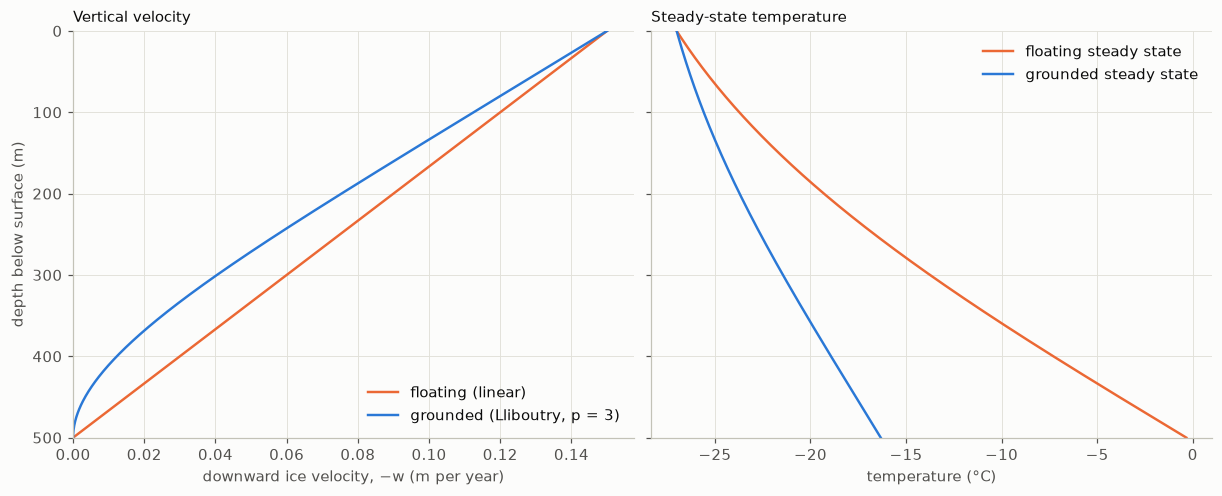

In [8]:
fig = plot_velocity_and_steady_states(ds)

### The floating phase

The column starts from a straight line and moves to the steady state, which matches the exact profile (circles). The rate of change falls by a factor of ten roughly every 1,300 years, so reaching the tolerance of 10⁻⁹ K per year takes 8,860 years. An ice shelf is unlikely to stay unchanged for that long. The steady state is a convenient starting point more than a realistic one, which the end of section 9 comes back to.

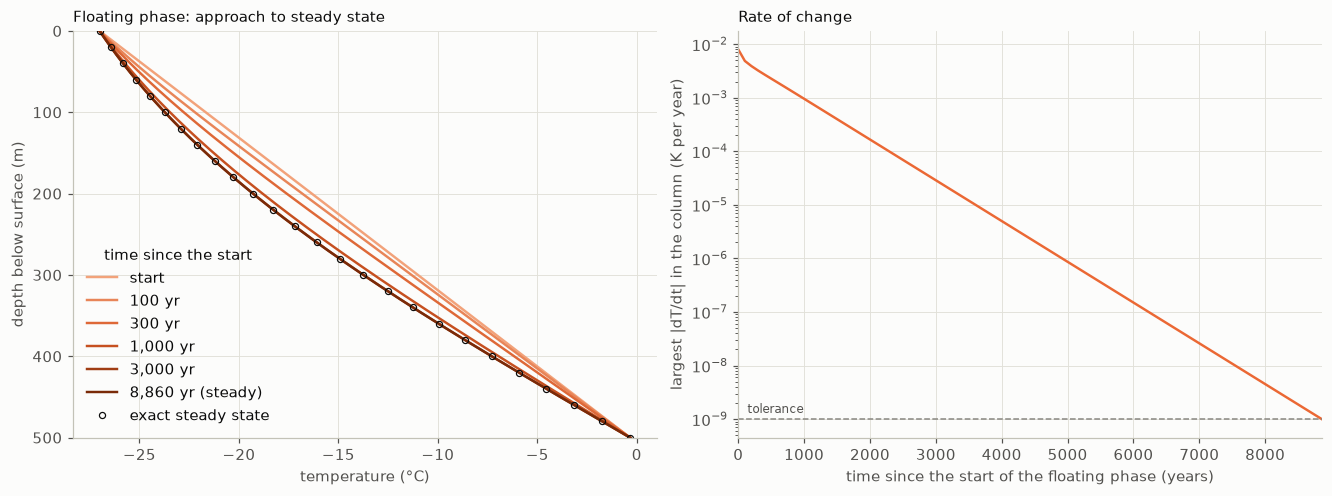

In [9]:
fig = plot_spinup(ds)

### Temperature profiles after grounding

While the ice was floating, its steady profile conducted 162 mW m⁻² away from the base, and the ocean made up for it by keeping the base at the melting point. After grounding only the geothermal flux of 60 mW m⁻² arrives. The base therefore cools, and it goes on cooling until the temperature gradient at the bed has fallen to $G/k$.

The cooling spreads upward from the bed. After 100 years only the lowest 135 m have cooled by more than 0.1 K. After 1,000 years almost the whole column has. After 5,000 years the bed is at −15.4 °C, within 0.9 K of its final value of −16.3 °C.

Higher in the column the ice at first warms slightly, by at most 0.11 K (at about 200 m depth, 200 years after grounding). This comes from the change of velocity profile at grounding: the Lliboutry profile brings cold ice down more slowly than the linear one. The cooling from below overtakes it within 1,000 years. It does not happen when the velocity profile is the same in both phases.

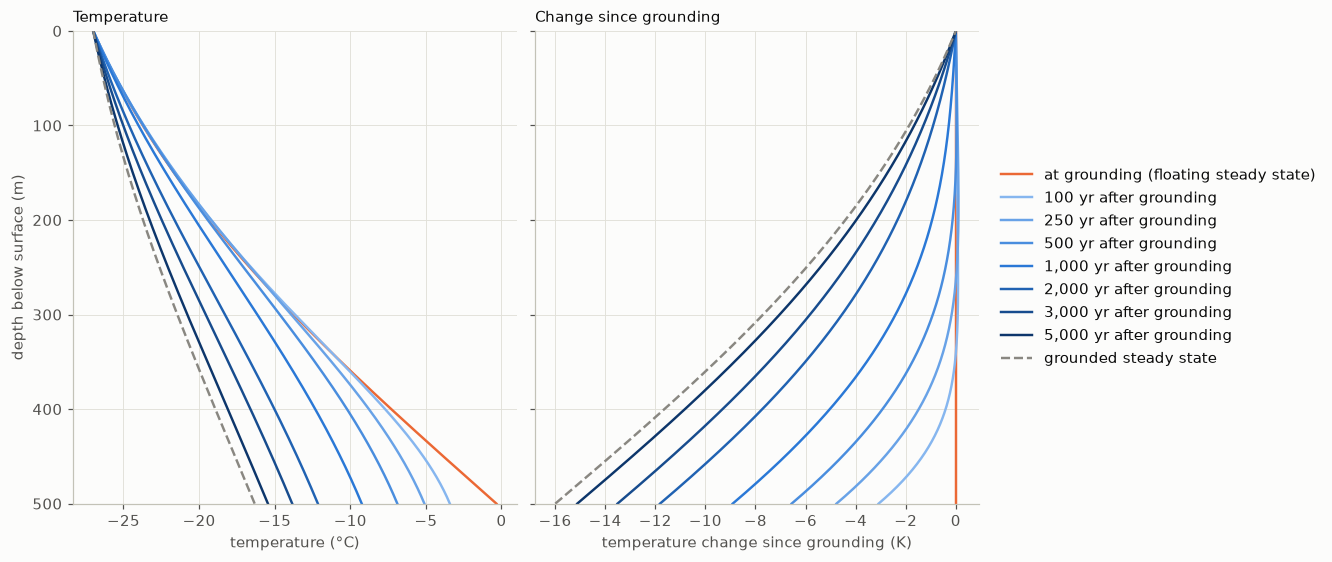

In [10]:
fig = plot_profiles(ds)

### Temperature in depth and time

Top: temperature, including the last 500 years of the floating phase. Bottom: the change since grounding. The contour lines are labelled in °C (top) and K (bottom). The slight early warming described above is too small to show on the colour scale of the bottom panel.

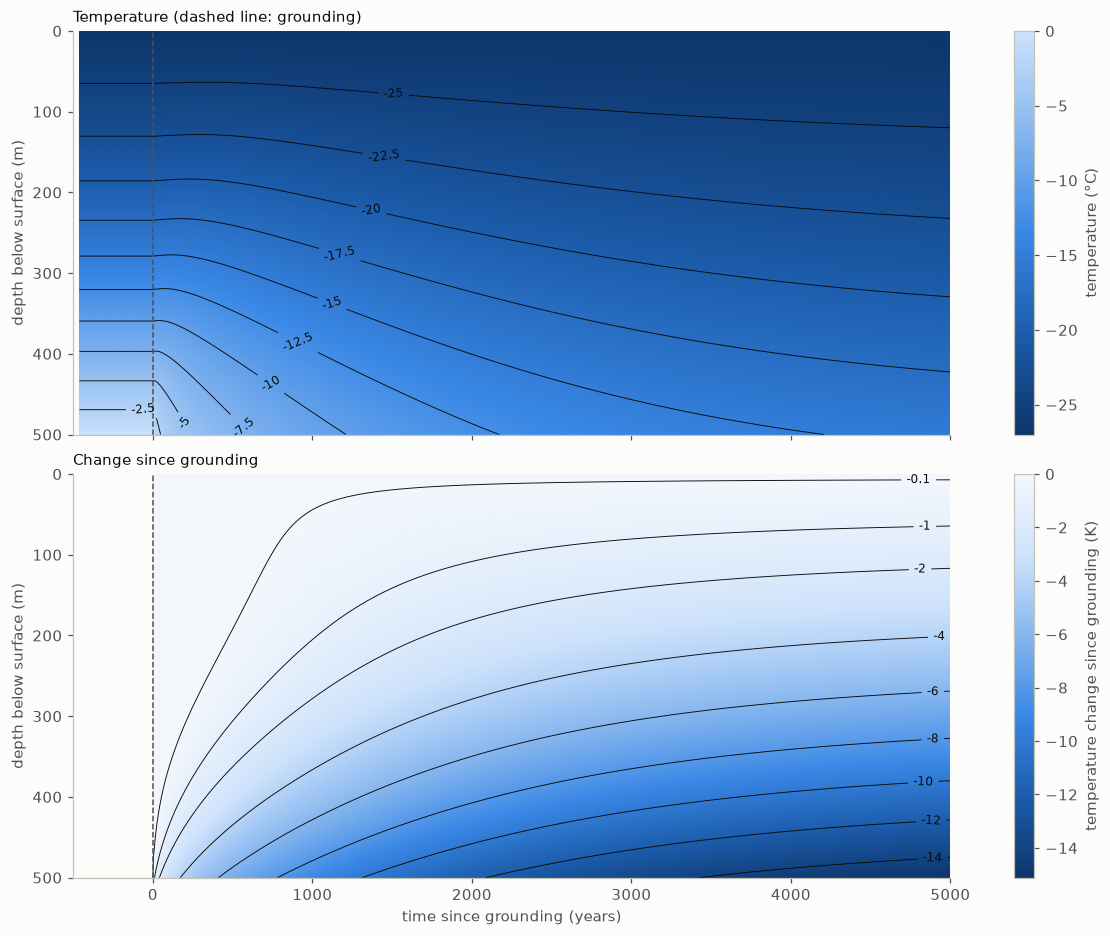

In [11]:
fig = plot_depth_time(ds)

### Temperature at fixed depths

Temperature at the bed and at the monitoring depths, again with the last 500 years of the floating phase. The table gives the values at the profile times.

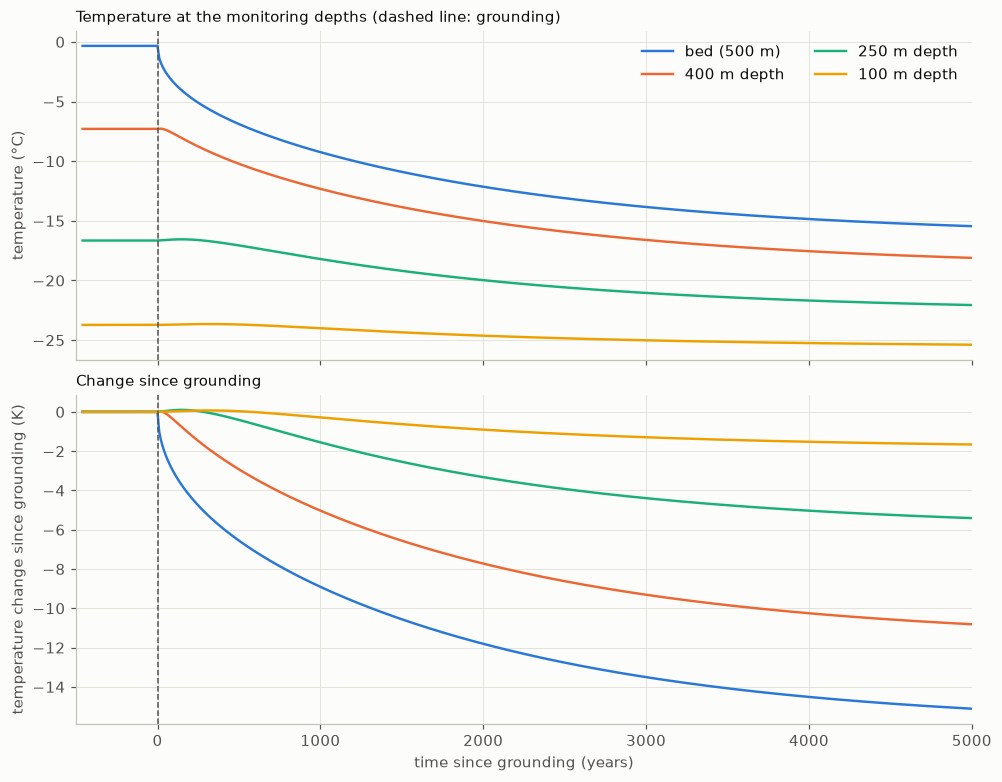

In [12]:
fig = plot_timeseries(ds)

In [13]:
print_temperature_table(ds)

Temperature (°C)                 100 m     250 m     400 m       bed
at grounding                    -23.72    -16.65     -7.29     -0.33
100 yr after grounding          -23.69    -16.56     -7.70     -3.42
250 yr after grounding          -23.66    -16.61     -8.77     -5.10
500 yr after grounding          -23.69    -17.06    -10.22     -6.89
1,000 yr after grounding        -24.01    -18.20    -12.32     -9.24
2,000 yr after grounding        -24.63    -19.97    -15.02    -12.14
3,000 yr after grounding        -25.02    -21.05    -16.60    -13.84
5,000 yr after grounding        -25.38    -22.06    -18.11    -15.45
grounded steady state           -25.58    -22.61    -18.93    -16.32


## 6. Save to NetCDF

Set `output_file` in section 2 to save the run. The dataset holds the full field `T(time, z)`, its rate of change `dTdt`, the time series `T_monitor(time, depth_monitor)`, the two velocity profiles, the two exact steady states, and every model parameter as a global attribute. To reload it later use `xr.open_dataset(...)`; the plotting functions above work on the reloaded dataset.

In [14]:
if params["output_file"]:
    ds.to_netcdf(params["output_file"])
    print(f"Saved {params['output_file']}")
else:
    print("Nothing saved: output_file is None.")

Nothing saved: output_file is None.


## 7. Checks

### (a) Steady states

The floating phase should end on the exact floating steady state of section 1, and a long enough grounded phase should end on the exact grounded steady state. The second is tested with a separate run of 30,000 years.

In [15]:
ds_long = run_model({**params, "grounded_years": 30_000.0, "output_interval_yr": 1000.0}, verbose=False)
error_floating = np.abs(ds["T"].sel(time=0.0) - ds["T_steady_floating"]).max().item()
error_grounded = np.abs(ds_long["T"].isel(time=-1) - ds_long["T_steady_grounded"]).max().item()
print(f"Floating phase, end of spin-up:      largest |model − exact| = {error_floating:.1e} K")
print(f"Grounded phase, after 30,000 years:  largest |model − exact| = {error_grounded:.1e} K")

Floating phase, end of spin-up:      largest |model − exact| = 2.4e-06 K
Grounded phase, after 30,000 years:  largest |model − exact| = 6.5e-06 K


Both agree to within a few millionths of a kelvin.

### (b) Grid and time-step convergence

The model is rerun with the grid spacing halved, with every time step halved, and with both halved, and each run is compared with the default run at every stored time of the grounded phase. Halving the time step means halving `dt_initial_yr`, `dt_max_yr` and (`dt_growth` − 1).

Largest change in temperature anywhere in the column, relative to the default run:
  grid spacing halved  1.2e-04 K at any stored time, 3.8e-05 K from 100 years after grounding
  time step halved     6.8e-06 K at any stored time, 4.8e-06 K from 100 years after grounding
  both halved          1.2e-04 K at any stored time, 3.3e-05 K from 100 years after grounding


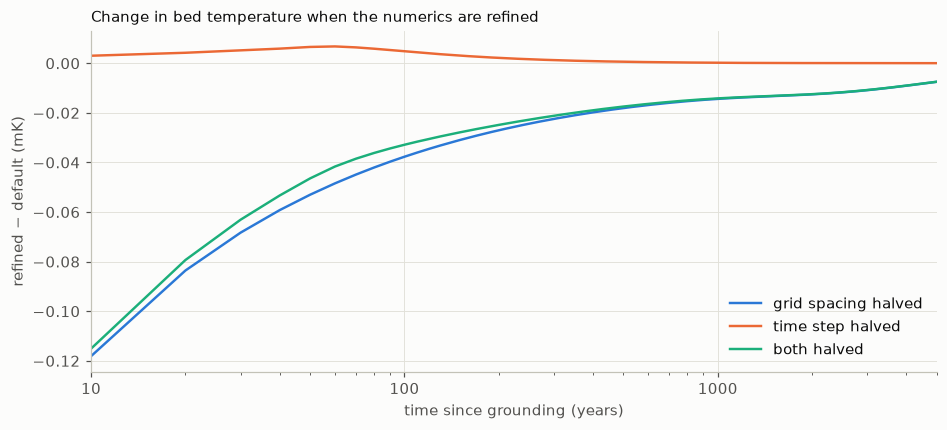

In [16]:
def refine(params, dz_factor=1, dt_factor=1):
    """Copy of params with the grid spacing divided by dz_factor and every time step divided by dt_factor."""
    refined = dict(params)
    refined["n_cells"] = params["n_cells"] * dz_factor
    refined["dt_initial_yr"] = params["dt_initial_yr"] / dt_factor
    refined["dt_growth"] = 1 + (params["dt_growth"] - 1) / dt_factor
    refined["dt_max_yr"] = params["dt_max_yr"] / dt_factor
    return refined


refinements = {
    "grid spacing halved": refine(params, dz_factor=2),
    "time step halved": refine(params, dt_factor=2),
    "both halved": refine(params, dz_factor=2, dt_factor=2),
}
grounded = ds["phase"].values == "grounded"
t_grounded = ds["time"].values[grounded]
differences = {}
for label, refined_params in refinements.items():
    ds_refined = run_model(refined_params, verbose=False)
    in_grounded = ds_refined["phase"].values == "grounded"
    assert np.allclose(ds_refined["time"].values[in_grounded], t_grounded), "runs must share output times"
    every = refined_params["n_cells"] // params["n_cells"]   # compare on the nodes of the default grid
    differences[label] = ds_refined["T"].values[in_grounded][:, ::every] - ds["T"].values[grounded]

print("Largest change in temperature anywhere in the column, relative to the default run:")
for label, difference in differences.items():
    print(f"  {label:<20s} {np.abs(difference).max():.1e} K at any stored time, "
          f"{np.abs(difference[t_grounded >= 100]).max():.1e} K from 100 years after grounding")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for (label, difference), colour in zip(differences.items(), SERIES_COLOURS):
    ax.plot(t_grounded, difference[:, 0] * 1e3, color=colour, label=label)
ax.set_xscale("log")
ax.xaxis.set_major_formatter("{x:g}")
ax.set_xlim(t_grounded.min(), t_grounded.max())
ax.set_xlabel("time since grounding (years)")
ax.set_ylabel("refined − default (mK)")
ax.set_title("Change in bed temperature when the numerics are refined")
ax.legend(loc="lower right")
plt.show()

Halving the time step changes the temperature by less than 0.01 mK, so the time stepping contributes almost nothing to the error. Halving the grid spacing changes the bed temperature by 0.12 mK ten years after grounding and by less than 0.04 mK from 100 years on. The scheme is second-order accurate in space, so halving the spacing removes about three quarters of the spatial error, and the error of the default run is about four thirds of that change.

### (c) Grounded phase against an exact solution with no accumulation

With $a = 0$ there is no advection, the floating steady state is a straight line, and the temperature after grounding is

$$T(z, t) = T_s + \frac{G}{k}\,(H - z) + \sum_{n=0}^{\infty}\frac{2A}{(\lambda_n H)^2}\,\cos(\lambda_n z)\,e^{-\kappa\lambda_n^2 t}, \qquad \lambda_n = \frac{(n + \tfrac{1}{2})\,\pi}{H}, \qquad A = T_m - T_s - \frac{GH}{k}.$$

The first two terms are the grounded steady state and the sum is the decaying difference from it. This tests the heat-flux boundary condition and the time stepping after the change of boundary condition, but not the advection term, which is tested by the steady states in (a).

No accumulation: largest |model − exact| over the column
      10 yr after grounding: 9.4e-05 K
     100 yr after grounding: 2.7e-05 K
   1,000 yr after grounding: 9.6e-06 K
   5,000 yr after grounding: 3.8e-06 K


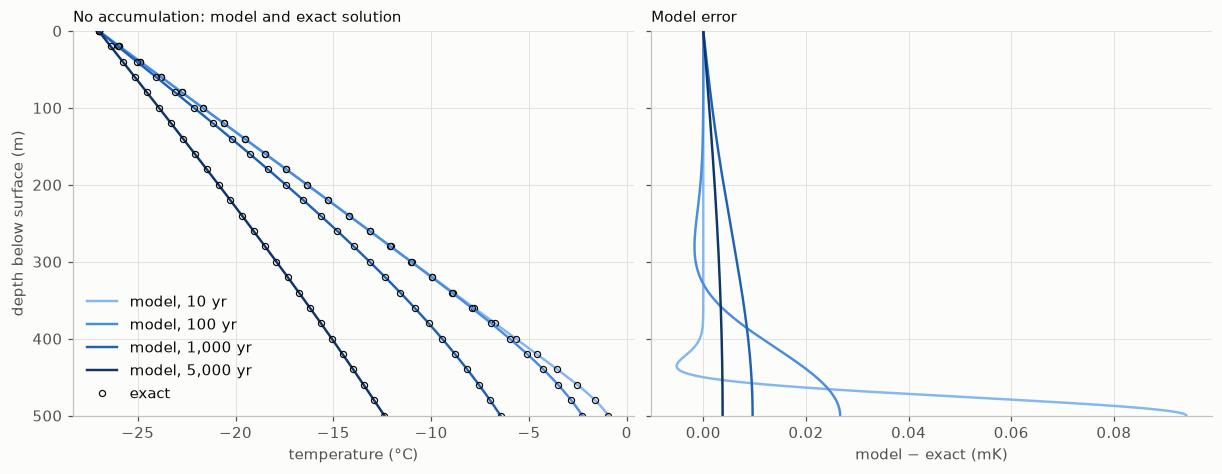

In [17]:
def exact_conduction_only(z, t, p):
    """Exact T(z, t) (°C) after grounding when there is no advection; t in years after grounding."""
    H, kappa = p["H"], thermal_diffusivity(p)
    gradient = p["geothermal_flux"] / p["k"]
    amplitude = floating_base_temperature(p) - p["T_surface"] - gradient * H
    eigen = (np.arange(4000) + 0.5) * np.pi / H
    series = (2 * amplitude / (eigen * H) ** 2 * np.exp(-kappa * eigen**2 * t)) @ np.cos(np.outer(eigen, z))
    return p["T_surface"] + gradient * (H - z) + series


def check_against_exact_solution(params, times=(10, 100, 1000, 5000)):
    """Run the model with no accumulation and compare the grounded phase with the exact series solution."""
    no_advection = {**params, "accumulation": 0.0, "profile_times_yr": list(times)}
    ds_check = run_model(no_advection, verbose=False)
    z, depth = ds_check["z"].values, ds_check["depth"].values
    marked = slice(None, None, max(1, z.size // 25))

    fig, (ax_T, ax_error) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    print("No accumulation: largest |model − exact| over the column")
    for t, colour in zip(times, sample_ramp(GROUNDED_RAMP, len(times))):
        T_model = ds_check["T"].sel(time=t).values
        T_exact = exact_conduction_only(z, t, no_advection)
        print(f"  {format_years(t):>9s} after grounding: {np.abs(T_model - T_exact).max():.1e} K")
        ax_T.plot(T_model, depth, color=colour, label=f"model, {format_years(t)}")
        ax_T.plot(T_exact[marked], depth[marked], "o", markersize=4, markerfacecolor="none", markeredgecolor=INK,
                  markeredgewidth=0.8, label="exact" if t == times[-1] else None)
        ax_error.plot((T_model - T_exact) * 1e3, depth, color=colour)
    depth_axis(ax_T, no_advection["H"])
    ax_T.set_xlabel("temperature (°C)")
    ax_T.set_title("No accumulation: model and exact solution")
    ax_T.legend(loc="lower left")
    ax_error.set_xlabel("model − exact (mK)")
    ax_error.set_title("Model error")
    return fig


fig = check_against_exact_solution(params)

The model is within 0.1 mK of the exact solution ten years after grounding and within 0.03 mK from 100 years on. The error is largest at the bed just after grounding, where the temperature changes fastest.

## 8. Rerun with different parameters

`run_model` takes a parameter dictionary and returns a dataset, so a different case is a modified copy of `params`. This example varies the accumulation rate, the geothermal heat flux and the choice of velocity profile, and plots the bed temperature after grounding. The second case in each panel is the default run. The short dotted lines at the right-hand edge mark the grounded steady state of each case.

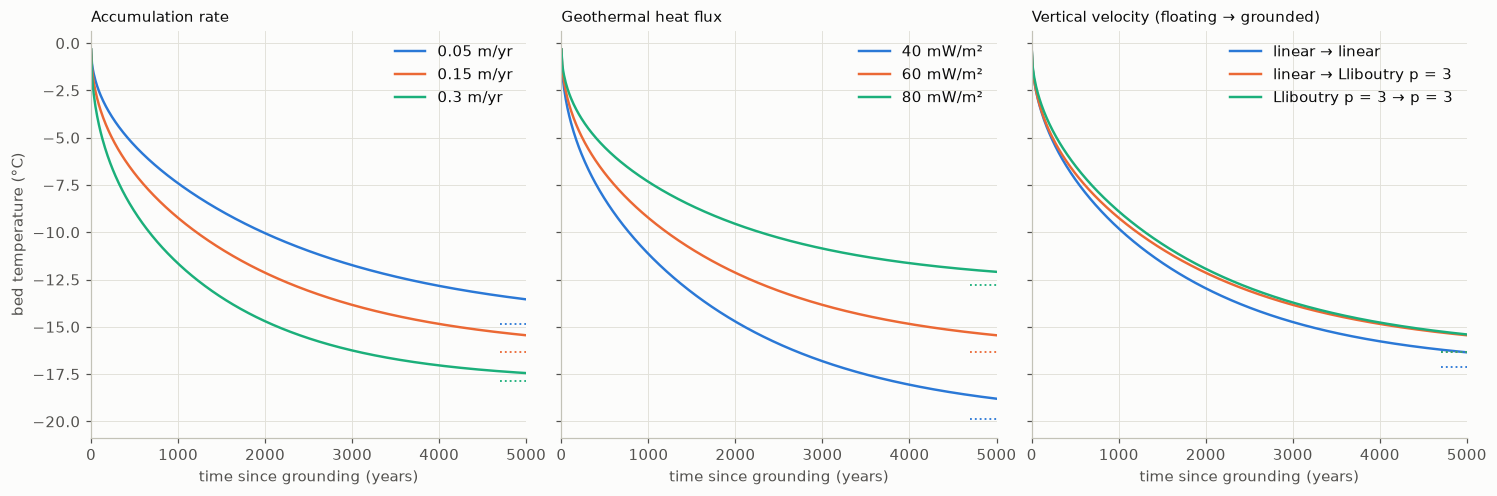

Bed temperature (°C)              after 1,000 yr  after 5,000 yr  steady state
Accumulation rate
  0.05 m/yr                                -7.41          -13.55        -14.87
  0.15 m/yr                                -9.24          -15.45        -16.32
  0.3 m/yr                                -11.65          -17.45        -17.87
Geothermal heat flux
  40 mW/m²                                -11.15          -18.80        -19.88
  60 mW/m²                                 -9.24          -15.45        -16.32
  80 mW/m²                                 -7.34          -12.09        -12.76
Vertical velocity (floating → grounded)
  linear → linear                          -9.80          -16.35        -17.13
  linear → Lliboutry p = 3                 -9.24          -15.45        -16.32
  Lliboutry p = 3 → p = 3                  -8.90          -15.40        -16.32


In [18]:
# The second case of each sweep is the default run, so it has the same colour in every panel.
sweeps = {
    "Accumulation rate": {f"{a:g} m/yr": {"accumulation": a} for a in (0.05, 0.15, 0.30)},
    "Geothermal heat flux": {f"{1e3 * G:g} mW/m²": {"geothermal_flux": G} for G in (0.040, 0.060, 0.080)},
    "Vertical velocity (floating → grounded)": {
        "linear → linear": {"p_floating": np.inf, "p_grounded": np.inf},
        "linear → Lliboutry p = 3": {"p_floating": np.inf, "p_grounded": 3.0},
        "Lliboutry p = 3 → p = 3": {"p_floating": 3.0, "p_grounded": 3.0},
    },
}
sweep_runs = {sweep: {label: run_model({**params, **changes}, verbose=False) for label, changes in cases.items()}
              for sweep, cases in sweeps.items()}

fig, axes = plt.subplots(1, len(sweep_runs), figsize=(13.5, 4.4), sharey=True)
for ax, (sweep, runs) in zip(axes, sweep_runs.items()):
    for (label, ds_case), colour in zip(runs.items(), SERIES_COLOURS):
        after = ds_case["time"].values >= 0
        ax.plot(ds_case["time"].values[after], ds_case["T"].values[after, 0], color=colour, label=label)
        # Short dotted line at the right-hand edge: the grounded steady state of this case
        t_end = ds_case["time"].values[-1]
        ax.plot([0.94 * t_end, t_end], [ds_case["T_steady_grounded"].values[0]] * 2, color=colour,
                linewidth=1.2, linestyle=":")
    ax.set_xlim(0, t_end)
    ax.set_xlabel("time since grounding (years)")
    ax.set_title(sweep)
    ax.legend(loc="upper right")
axes[0].set_ylabel("bed temperature (°C)")
plt.show()

print(f"{'Bed temperature (°C)':<32}{'after 1,000 yr':>16}{'after 5,000 yr':>16}{'steady state':>14}")
for sweep, runs in sweep_runs.items():
    print(sweep)
    for label, ds_case in runs.items():
        bed = ds_case["T"].sel(time=[1000.0, 5000.0]).values[:, 0]
        print(f"{'  ' + label:<32}{bed[0]:16.2f}{bed[1]:16.2f}{ds_case['T_steady_grounded'].values[0]:14.2f}")

- A higher accumulation rate cools the bed faster and further, because more cold ice is carried down.
- A higher geothermal heat flux means less cooling. A change of 20 mW m⁻² changes the bed temperature after 5,000 years by 3.4 K.
- The velocity profile matters less. Keeping the linear profile after grounding leaves the bed 0.9 K colder after 5,000 years. Using the Lliboutry profile in both phases changes the bed temperature by 0.3 K after 1,000 years and by less than 0.1 K after 5,000.

Any other parameter can be changed the same way, for example:

```python
ds_sea = run_model({**params, "T_base_floating": -2.2})        # base at the freezing point of sea water while floating
ds_thick = run_model({**params, "H": 700.0, "n_cells": 700})   # thicker ice
ds_long = run_model({**params, "grounded_years": 20_000.0})    # longer grounded phase
fig = plot_profiles(ds_sea)
```

## 9. How precisely does the temperature need to be measured to date the grounding?

A temperature profile measured in a borehole today is one vertical slice through the depth–time plot of section 5. It can tell us when the ice grounded only if two things hold. The profile must still be changing fast enough for the time since grounding to make a measurable difference. And that difference must not look like the effect of something else that is not known. Sections 9.1 and 9.2 take these in turn, section 9.3 combines them into the uncertainty of the grounding time for a given sensor precision, and section 9.4 tests the result on an example.

Throughout, the precision of a sensor means the standard deviation of the error in the ice temperature assigned to its depth, after whatever correction has been made for the heat left by drilling. The [borehole heat-diffusion notebook](borehole-heat-diffusion.ipynb) looks at that correction.

### 9.1 How fast the profile is changing

If everything about the column except the grounding time were known, one sensor would be enough: an error $\delta T$ in its temperature gives an error $\delta T / |\partial T/\partial t|$ in the time since grounding. The left panel shows the rate of change of temperature at six times. The right panel and the table multiply it by 100 years, which gives the temperature difference between two profiles whose grounding times differ by a century.

Slowest-decaying temperature pattern in the grounded column: e-folding time 1,921 yr
Second slowest:                                              e-folding time 271 yr


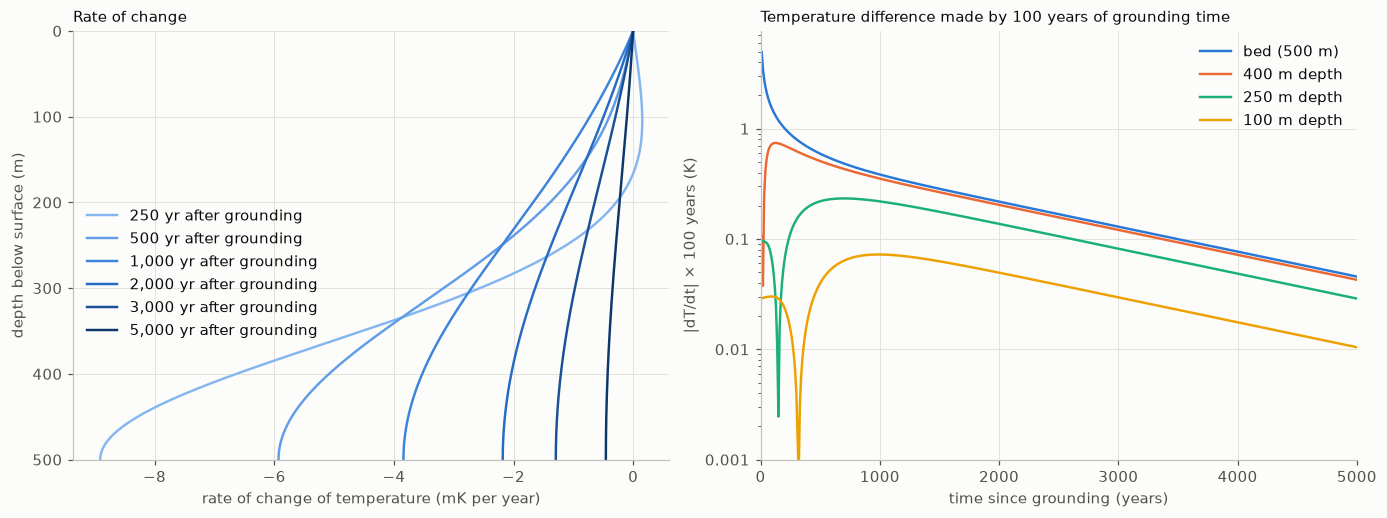

In [19]:
def decay_times(ds, n=2):
    """e-folding times (years) of the n slowest-decaying temperature patterns in the grounded column.

    They are -1 / eigenvalue of the grounded-phase operator L, with the surface node held fixed.
    """
    z = ds["z"].values
    L, _ = build_operator(z, ds.attrs["kappa_m2_per_yr"], ds["w_grounded"].values, "gradient")
    free = z.size - 1   # every node except the surface
    matrix = np.diag(L[1, :free]) + np.diag(L[0, 1:free], 1) + np.diag(L[2, :free - 1], -1)
    return 1 / np.sort(-np.linalg.eigvals(matrix).real)[:n]


def plot_rate_of_change(ds, ages=(250, 500, 1000, 2000, 3000, 5000), resolve_years=100.0):
    """How fast the grounded column is cooling.

    Left: dT/dt against depth at `ages` (years after grounding). Right: the size of the temperature
    difference made by `resolve_years` of grounding time, |dT/dt| x resolve_years, at the monitoring depths.
    """
    a = ds.attrs
    depth = ds["depth"].values
    ages = [t for t in ages if 0 < t <= a["grounded_years"]]
    fig, (ax_rate, ax_signal) = plt.subplots(1, 2, figsize=(12.5, 4.6))
    for t, colour in zip(ages, sample_ramp(GROUNDED_RAMP, len(ages))):
        ax_rate.plot(1e3 * ds["dTdt"].sel(time=t, method="nearest").values, depth, color=colour,
                     label=f"{format_years(t)} after grounding")
    depth_axis(ax_rate, a["H"])
    ax_rate.set_xlabel("rate of change of temperature (mK per year)")
    ax_rate.set_title("Rate of change")
    ax_rate.legend(loc="lower left", bbox_to_anchor=(0.0, 0.25))

    after = ds["time"].values > 0
    rate = at_depths(ds, ds["depth_monitor"].values, "dTdt")
    for depth_monitor, colour in zip(ds["depth_monitor"].values[::-1], SERIES_COLOURS):
        label = f"bed ({depth_monitor:g} m)" if np.isclose(depth_monitor, a["H"]) else f"{depth_monitor:g} m depth"
        ax_signal.plot(ds["time"].values[after],
                       np.abs(rate.sel(depth_monitor=depth_monitor).values[after]) * resolve_years,
                       color=colour, label=label)
    ax_signal.set_yscale("log")
    ax_signal.yaxis.set_major_formatter("{x:g}")
    ax_signal.set_xlim(0, a["grounded_years"])
    ax_signal.set_ylim(1e-3, None)
    ax_signal.set_xlabel("time since grounding (years)")
    ax_signal.set_ylabel(f"|dT/dt| × {resolve_years:g} years (K)")
    ax_signal.set_title(f"Temperature difference made by {resolve_years:g} years of grounding time")
    ax_signal.legend(loc="upper right")
    return fig


slowest, second = decay_times(ds)
print(f"Slowest-decaying temperature pattern in the grounded column: e-folding time {slowest:,.0f} yr")
print(f"Second slowest:                                              e-folding time {second:,.0f} yr")
fig = plot_rate_of_change(ds)

In [20]:
print("Temperature difference (K) made by 100 years of grounding time, |dT/dt| × 100 yr")
depths = ds["depth_monitor"].values[::-1]
print(" " * 24 + "".join(f"{('bed' if np.isclose(d, params['H']) else f'{d:g} m'):>10}" for d in depths))
for t in params["profile_times_yr"]:
    rate = at_depths(ds, depths, "dTdt").sel(time=t, method="nearest").values
    print(f"{format_years(t) + ' after grounding':<24}" + "".join(f"{100 * abs(value):10.3f}" for value in rate))

Temperature difference (K) made by 100 years of grounding time, |dT/dt| × 100 yr
                               bed     400 m     250 m     100 m
100 yr after grounding       1.486     0.730     0.060     0.030
250 yr after grounding       0.891     0.663     0.112     0.015
500 yr after grounding       0.593     0.508     0.220     0.040
1,000 yr after grounding     0.384     0.353     0.219     0.072
2,000 yr after grounding     0.218     0.204     0.137     0.050
3,000 yr after grounding     0.129     0.121     0.082     0.030
5,000 yr after grounding     0.046     0.043     0.029     0.010


A century of grounding time changes the bed temperature by 0.38 K if the ice grounded 1,000 years ago, by 0.22 K at 2,000 years and by 0.05 K at 5,000 years.

The cooling slows because the column is relaxing towards its grounded steady state. Its difference from that state is a sum of patterns, each of which decays exponentially at its own rate. The slowest has an e-folding time of 1,921 years and the next 271 years. After 1,000 to 1,500 years little but the slowest pattern is left, and from then on the rate of change at every depth falls by the same factor every year: the parallel straight lines in the right-hand panel. (The dips in the curves for 250 m and 100 m are where the temperature at that depth stops warming and starts cooling.)

### 9.2 Other things that are not known

A fit to a measured profile would have to find more than the grounding time. The geothermal heat flux is poorly known. The accumulation rate and surface temperature can be measured today, but not as averages over thousands of years. The velocity profile, and the temperature of the base of the ice when it grounded, are assumptions.

The figure shows how the temperature at each sensor depth changes when each of these is changed by the amount given in the legend, for ice that grounded 1,000 and 3,000 years ago. The blue line is the effect of grounding 100 years earlier. The sensors are at the depths in `sensor_depths`: one every 20 m, with the deepest at the bed.

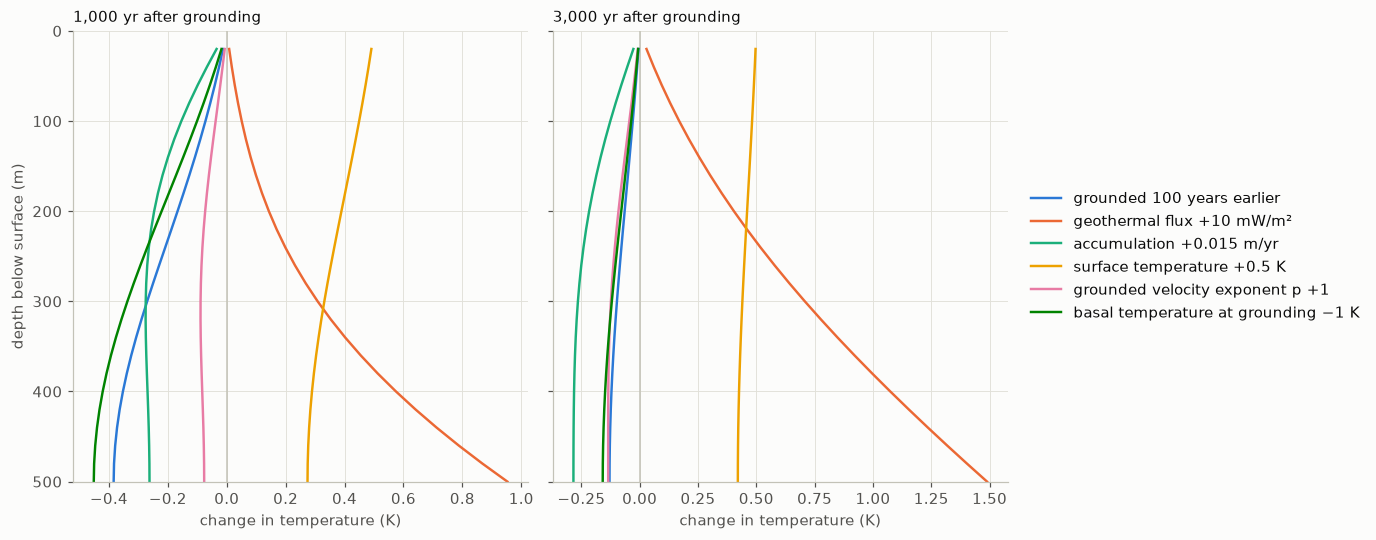

In [21]:
# Depths (m below the surface) of the temperature sensors: one every 20 m, the deepest at the bed.
sensor_depths = np.arange(20.0, 501.0, 20.0)

# Quantities other than the grounding time that a fit to a measured profile may also have to find.
#   step  : change used to compute the sensitivity by central differences
#   shown : change whose effect on the profile is drawn in the figure below
#   prior : how well the quantity is known beforehand (1 standard deviation), or None for not at all
other_unknowns = {
    "geothermal_flux": dict(step=1e-3, shown=0.010, shown_label="geothermal flux +10 mW/m²", prior=None),
    "accumulation": dict(step=1e-3, shown=0.015, shown_label="accumulation +0.015 m/yr", prior=None),
    "T_surface": dict(step=0.01, shown=0.5, shown_label="surface temperature +0.5 K", prior=None),
    "p_grounded": dict(step=0.05, shown=1.0, shown_label="grounded velocity exponent p +1", prior=None),
    # The grounding time cannot be separated from this one at late times (see below), so it needs a prior.
    "T_base_floating": dict(step=0.01, shown=-1.0, shown_label="basal temperature at grounding −1 K", prior=1.0),
}


def sensor_values(ds, variable="T"):
    """Values at the sensor depths for every stored time of the grounded phase: array (n_age, n_sensor)."""
    return at_depths(ds, sensor_depths, variable).values[ds["phase"].values == "grounded"]


def profile_sensitivities(params, other_unknowns):
    """Sensitivity of the temperature at the sensors to the grounding time and to each other unknown.

    Returns (ages, sensitivities). ages are the stored times since grounding (years). sensitivities maps
    "age" to dT/dt (K per year) and every other name to dT/d(parameter). Each array is (n_age, n_sensor).
    """
    reference = {**params, "T_base_floating": floating_base_temperature(params)}   # a number, so it can be changed
    ds_reference = run_model(reference, verbose=False)
    ages = ds_reference["time"].values[ds_reference["phase"].values == "grounded"]
    sensitivities = {"age": sensor_values(ds_reference, "dTdt")}
    for name, info in other_unknowns.items():
        if not np.isfinite(reference[name]):
            raise ValueError(f"{name} is not finite, so it cannot be varied. Remove it from other_unknowns.")
        up = sensor_values(run_model({**reference, name: reference[name] + info["step"]}, verbose=False))
        down = sensor_values(run_model({**reference, name: reference[name] - info["step"]}, verbose=False))
        sensitivities[name] = (up - down) / (2 * info["step"])
    return ages, sensitivities


def plot_signatures(ages, sensitivities, shown_ages=(1000, 3000), earlier_years=100.0):
    """Change in the temperature at the sensors caused by a change in each unknown, at `shown_ages`."""
    fig, axes = plt.subplots(1, len(shown_ages), figsize=(6.2 * len(shown_ages), 4.8), sharey=True, squeeze=False)
    for ax, age in zip(axes[0], shown_ages):
        i = np.argmin(np.abs(ages - age))
        ax.axvline(0, color=AXIS_LINE, linewidth=1)
        ax.plot(sensitivities["age"][i] * earlier_years, sensor_depths, color=SERIES_COLOURS[0],
                label=f"grounded {earlier_years:g} years earlier")
        for (name, info), colour in zip(other_unknowns.items(), SERIES_COLOURS[1:]):
            ax.plot(sensitivities[name][i] * info["shown"], sensor_depths, color=colour, label=info["shown_label"])
        ax.set_xlabel("change in temperature (K)")
        ax.set_title(f"{format_years(ages[i])} after grounding")
    depth_axis(axes[0, 0], params["H"])
    axes[0, -1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    return fig


ages, sensitivities = profile_sensitivities(params, other_unknowns)
fig = plot_signatures(ages, sensitivities)

After 1,000 years the curves have different shapes. A higher geothermal flux warms the bed most, a higher accumulation rate cools the whole lower half of the column, a warmer surface warms the top most, and so on. A profile with sensors through the whole column can tell them apart.

After 3,000 years three of the curves are hard to tell apart: grounding earlier, a larger velocity exponent, and a colder base at grounding. The first two can still be separated by precise enough sensors, because the velocity exponent also changes the steady state that the column is heading for. The first and last cannot. By then only the slowest-decaying pattern of section 9.1 is left of the starting state. Grounding earlier gives that pattern longer to decay, and a colder base at grounding gives it a smaller size to begin with. The profile cannot distinguish the two.

### 9.3 Uncertainty of the grounding time

Suppose the temperature is measured at the 25 sensor depths, and the errors of the sensors are independent with standard deviation $\sigma$. A model like this one is fitted to the readings by least squares, adjusting the time since grounding together with whichever other quantities are not known. For small errors the covariance of the fitted quantities is

$$\mathbf{C} = \left(\frac{\mathbf{J}^\mathsf{T}\mathbf{J}}{\sigma^2} + \mathbf{P}\right)^{-1}.$$

Each column of $\mathbf{J}$ is the sensitivity of the sensor temperatures to one quantity: the curves of section 9.2 for a unit change, with $\partial T/\partial t$ as the first column. $\mathbf{P}$ is diagonal, with $1/s^2$ for a quantity that is already known to within a standard deviation $s$, and zero for one that is not known at all. The uncertainty of the grounding time is the square root of the first diagonal element of $\mathbf{C}$. No fit to these sensors can do better without more information, and a real fit will do worse to the extent that the model is wrong.

Three cases are compared:

1. Only the grounding time is unknown.
2. The geothermal heat flux $G$, accumulation rate $a$, surface temperature and velocity exponent $p$ are also unknown, with nothing known about any of them beforehand.
3. As case 2, and the basal temperature at grounding is known only to within ±1 K. (The two values mentioned in section 1, −0.33 °C and −2.2 °C, are 1.9 K apart.)

In the figure the dashed line marks an uncertainty of 10 % of the time since grounding. The tables below it give the same results as numbers, and then the other way round: the sensor precision needed to reach a given uncertainty.

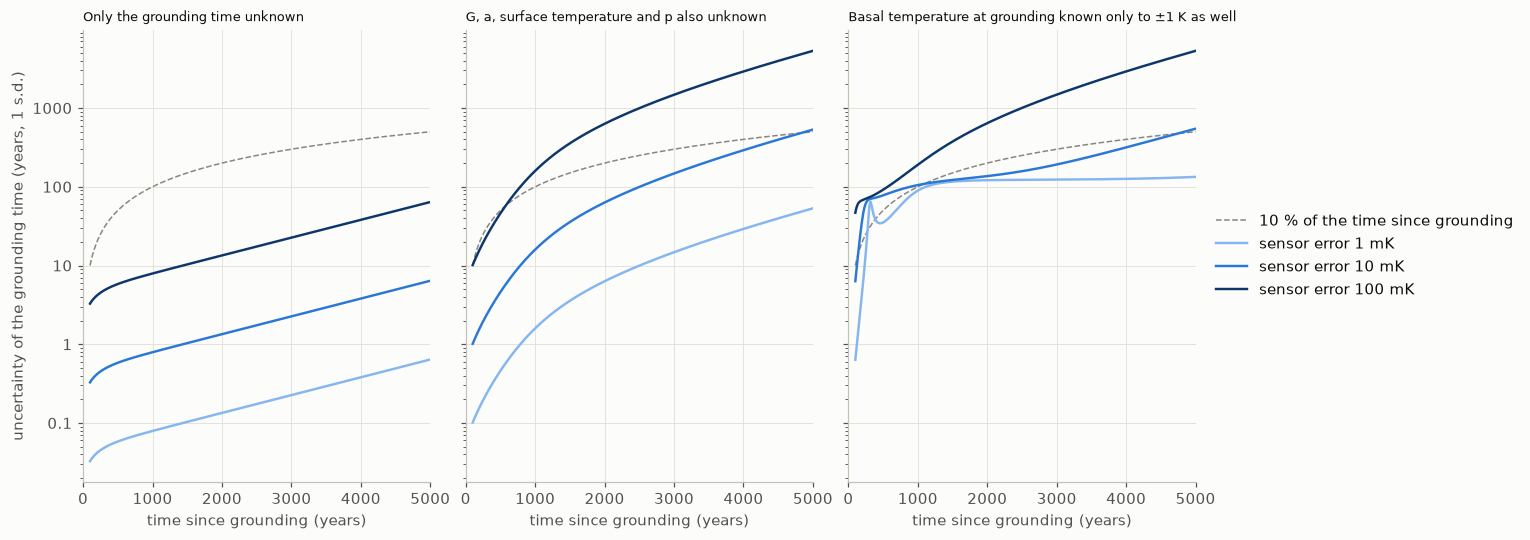

In [22]:
# Which of the other unknowns are fitted along with the grounding time, in three cases
cases = {
    "Only the grounding time unknown": [],
    "G, a, surface temperature and p also unknown": ["geothermal_flux", "accumulation", "T_surface", "p_grounded"],
    "Basal temperature at grounding known only to ±1 K as well": [
        "geothermal_flux", "accumulation", "T_surface", "p_grounded", "T_base_floating"],
}
sensor_noise_K = [0.001, 0.01, 0.1]   # standard deviation of the error of one sensor (K)


def grounding_time_uncertainty(sensitivities, unknowns, noise_K):
    """Standard deviation (years) of the grounding time estimated from one profile, at every stored age.

    Linearised least squares. The error of each sensor is independent with standard deviation noise_K,
    and the grounding time is fitted together with the quantities named in `unknowns`. A quantity
    with a prior in other_unknowns is treated as already known to within that standard deviation.
    """
    names = ["age", *unknowns]
    J = np.stack([sensitivities[name] for name in names], axis=-1)   # (n_age, n_sensor, n_unknown)
    scale = np.sqrt((J**2).sum(axis=1))                              # (n_age, n_unknown): size of each column
    J = J / scale[:, np.newaxis, :]                                  # unit columns keep the matrix well conditioned
    information = np.einsum("asi,asj->aij", J, J) / noise_K**2
    for i, name in enumerate(unknowns, start=1):
        prior = other_unknowns[name]["prior"]
        if prior is not None:
            information[:, i, i] += 1 / (prior * scale[:, i]) ** 2
    covariance = np.linalg.inv(information)
    return np.sqrt(covariance[:, 0, 0]) / scale[:, 0]


def required_precision(sensitivities, unknowns, target_years):
    """Largest sensor noise (K) that keeps the grounding-time uncertainty within target_years, at every age.

    target_years is a number or an array with one value per age. The result is NaN where no precision
    is good enough, and inf where 10 K (the coarsest tried) is.
    """
    trial_noise = np.geomspace(1e-7, 10.0, 161)
    sigma = np.array([grounding_time_uncertainty(sensitivities, unknowns, noise) for noise in trial_noise])
    target = np.broadcast_to(np.asarray(target_years, dtype=float), sigma.shape[1:])
    needed = np.full(target.shape, np.nan)
    for i in range(target.size):   # the uncertainty always grows with the noise, so interpolate on it
        if target[i] >= sigma[-1, i]:
            needed[i] = np.inf
        elif target[i] >= sigma[0, i]:
            needed[i] = np.exp(np.interp(np.log(target[i]), np.log(sigma[:, i]), np.log(trial_noise)))
    return needed


def plot_grounding_time_uncertainty(ages, sensitivities, cases, sensor_noise_K, first_age=100.0):
    """Uncertainty of the grounding time against the time since grounding, one panel per case."""
    shown = ages >= first_age
    fig, axes = plt.subplots(1, len(cases), figsize=(4.6 * len(cases), 4.8), sharex=True, sharey=True, squeeze=False)
    for ax, (title, unknowns) in zip(axes[0], cases.items()):
        ax.plot(ages[shown], 0.1 * ages[shown], color=INK_MUTED, linewidth=1, linestyle="--",
                label="10 % of the time since grounding")
        for noise, colour in zip(sensor_noise_K, sample_ramp(GROUNDED_RAMP, len(sensor_noise_K))):
            sigma = grounding_time_uncertainty(sensitivities, unknowns, noise)
            ax.plot(ages[shown], sigma[shown], color=colour, label=f"sensor error {1e3 * noise:g} mK")
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter("{x:g}")
        ax.set_xlim(0, ages.max())
        ax.set_xlabel("time since grounding (years)")
        ax.set_title(title, fontsize="small")
    axes[0, 0].set_ylabel("uncertainty of the grounding time (years, 1 s.d.)")
    axes[0, -1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    return fig


fig = plot_grounding_time_uncertainty(ages, sensitivities, cases, sensor_noise_K)

In [23]:
def format_uncertainty(years):
    """Grounding-time uncertainty for the tables, in years."""
    return f"{years:,.0f}" if years >= 10 else (f"{years:.1f}" if years >= 1 else f"{years:.2f}")


def format_precision(noise_K):
    """Sensor precision for the tables, in mK."""
    if np.isnan(noise_K):
        return "not reachable"
    if np.isinf(noise_K):
        return "> 10,000"
    if noise_K < 1e-5:
        return "< 0.01"
    return f"{1e3 * noise_K:,.0f}" if noise_K >= 0.1 else f"{1e3 * noise_K:.2g}"


table_ages = [500, 1000, 2000, 3000, 4000, 5000]
rows = [np.argmin(np.abs(ages - age)) for age in table_ages]

print("Uncertainty of the grounding time (years, 1 s.d.) for three sensor precisions")
for n, (title, unknowns) in enumerate(cases.items(), start=1):
    print(f"\ncase {n}: {title}")
    print(f"{'time since grounding':<24}" + "".join(f"{f'{1e3 * noise:g} mK':>10}" for noise in sensor_noise_K))
    sigma = [grounding_time_uncertainty(sensitivities, unknowns, noise) for noise in sensor_noise_K]
    for age, row in zip(table_ages, rows):
        print(f"{format_years(age):<24}" + "".join(f"{format_uncertainty(column[row]):>10}" for column in sigma))

targets = {"to within ±100 years": 100.0, "to within ±10 % of the time since grounding": 0.1 * ages}
for target_label, target in targets.items():
    print(f"\n\nSensor precision (mK, 1 s.d.) needed to date the grounding {target_label}")
    print(f"{'time since grounding':<24}" + "".join(f"{f'case {n}':>16}" for n in range(1, len(cases) + 1)))
    needed = [required_precision(sensitivities, unknowns, target) for unknowns in cases.values()]
    for age, row in zip(table_ages, rows):
        print(f"{format_years(age):<24}" + "".join(f"{format_precision(column[row]):>16}" for column in needed))

Uncertainty of the grounding time (years, 1 s.d.) for three sensor precisions

case 1: Only the grounding time unknown
time since grounding          1 mK     10 mK    100 mK
500 yr                        0.06      0.58       5.8
1,000 yr                      0.08      0.79       7.9
2,000 yr                      0.13       1.3        13
3,000 yr                      0.23       2.3        23
4,000 yr                      0.38       3.8        38
5,000 yr                      0.64       6.4        64

case 2: G, a, surface temperature and p also unknown
time since grounding          1 mK     10 mK    100 mK
500 yr                        0.46       4.6        46
1,000 yr                       1.6        16       159
2,000 yr                       6.3        63       631
3,000 yr                        15       148     1,475
4,000 yr                        29       292     2,915
5,000 yr                        53       532     5,324

case 3: Basal temperature at grounding known only to ±1 

500 yr                             1,718             217             132
1,000 yr                           1,263              63             2.1
2,000 yr                             745              16            0.03
3,000 yr                             443             6.8          < 0.01
4,000 yr                             263             3.4   not reachable
5,000 yr                             156             1.9   not reachable


Sensor precision (mK, 1 s.d.) needed to date the grounding to within ±10 % of the time since grounding
time since grounding              case 1          case 2          case 3


500 yr                               859             108             1.6
1,000 yr                           1,263              63             2.1
2,000 yr                           1,490              32              25
3,000 yr                           1,328              20              19
4,000 yr                           1,052              14              13
5,000 yr                             781             9.4             9.1


**Case 1.** If only the grounding time were unknown, sensor precision would hardly matter: errors of 100 mK would still date the grounding to within 64 years after 5,000 years.

**Case 2.** With the four other quantities fitted as well, the uncertainty is proportional to the sensor error, and it rises steeply with the time since grounding because the curves of section 9.2 become more alike as the column relaxes. With 10 mK sensors it is 16 years after 1,000 years, 63 after 2,000, 148 after 3,000 and 532 after 5,000. Dating the grounding to within ±100 years needs sensors good to 63 mK if the ice grounded 1,000 years ago, 16 mK at 2,000 years, 7 mK at 3,000 and 2 mK at 5,000. Dating it to within ±10 % needs 63, 32, 20 and 9 mK.

**Case 3.** A ±1 K uncertainty in the basal temperature at grounding adds 120 to 135 years that better sensors cannot remove once the ice has been grounded for more than about 1,500 years. With 1 mK sensors the total is 89 years after 1,000 years, and between 121 and 134 years from 2,000 years on. The two contributions combine roughly as the square root of the sum of their squares, so 10 mK sensors give 137 years after 2,000 years and 316 after 4,000. In the first 1,000 years the faster-decaying patterns have not yet died away, and precise sensors can use them to separate the grounding time from the starting temperature: 1 mK sensors give 35 years after 500 years.

The case 3 curves are not smooth in the first 500 years, with a peak near 300 years for 1 mK sensors. The same values come out when the calculation is repeated with a different matrix method and with different step sizes, so this is a property of the linearised problem and not numerical error. What causes it has not been looked into.

These numbers are for 25 sensors. With a sensor every 10 m the case 2 uncertainties are about 25 % smaller, and with one every 50 m about 40 % larger (found by changing `sensor_depths` and rerunning this section).

### 9.4 An example: two histories that give the same profile

The linearised estimate can be tested directly. Take the default run as the truth, in which the base of the ice was at −0.33 °C when it grounded. Fit its profile with a model that assumes the base was at −2.2 °C, the freezing point of sea water, adjusting only the time since grounding. The table gives the best-fitting time, its error, and the largest difference that remains between the fitted and the 'measured' temperatures at any sensor.

In [24]:
def best_fitting_age(ds_assumed, T_measured):
    """Time since grounding (years) at which the run ds_assumed best matches T_measured at the sensors.

    Least squares over the grounding time only. Returns (age, misfit at each sensor in K).
    """
    grounded_ages = ds_assumed["time"].values[ds_assumed["phase"].values == "grounded"]
    in_time = CubicSpline(grounded_ages, sensor_values(ds_assumed))   # the run's sensor temperatures at any age
    fit = minimize_scalar(lambda age: np.sum((in_time(age) - T_measured) ** 2),
                          bounds=(grounded_ages[0], grounded_ages[-1]), method="bounded", options={"xatol": 1e-6})
    return fit.x, in_time(fit.x) - T_measured


true_ages = [500, 1000, 1500, 2000, 3000, 4000]
assumed_base_temperature = -2.2   # °C: the freezing point of sea water at the ice base, instead of -0.33 °C
ds_assumed = run_model({**params, "T_base_floating": assumed_base_temperature}, verbose=False)
T_true = sensor_values(ds)

print(f"The 'measured' profiles come from the default run. They are fitted with a run in which the base\n"
      f"of the ice is at {assumed_base_temperature:g} °C when it grounds.\n")
print(f"{'true time since grounding':<28}{'best-fitting time':>18}{'error (yr)':>12}{'largest misfit (mK)':>22}")
for true_age in true_ages:
    fitted_age, misfit = best_fitting_age(ds_assumed, T_true[np.argmin(np.abs(ages - true_age))])
    largest = 1e3 * np.abs(misfit).max()
    print(f"{format_years(true_age):<28}{format_years(fitted_age):>18}{fitted_age - true_age:>+12.0f}"
          + (f"{largest:>22.0f}" if largest >= 10 else f"{largest:>22.2g}"))

The 'measured' profiles come from the default run. They are fitted with a run in which the base
of the ice is at -2.2 °C when it grounds.

true time since grounding    best-fitting time  error (yr)   largest misfit (mK)
500 yr                                  291 yr        -209                   329
1,000 yr                                760 yr        -240                    55
1,500 yr                              1,257 yr        -243                   8.6
2,000 yr                              1,757 yr        -243                   1.3
3,000 yr                              2,757 yr        -243                 0.033
4,000 yr                              3,757 yr        -243               0.00083


The wrong starting temperature makes the fitted grounding time about 240 years too recent, at every age from 1,000 years on. That is 130 years per kelvin, in line with case 3.

Whether the measurements could reveal that something is wrong depends on the size of the misfit. After 500 years it is 0.3 K and after 1,000 years 55 mK, which sensors good to 10 mK would detect. After 2,000 years it is 1.3 mK, and after 3,000 years 0.03 mK. From then on the two histories give the same profile to within any measurement, and no improvement in the sensors can separate them. (Only the grounding time was adjusted here. Adjusting the other unknowns as well would make the misfit smaller still.)

### What this shows

These numbers are for the default parameters, and for 25 sensors with independent errors.

- **After grounding the bed cools quickly at first and then slowly.** It is 3 K colder after 100 years, 9 K after 1,000 and 15 K after 5,000, and it ends 16 K colder. The cooling reaches almost the whole column within 1,000 years.
- **The signal itself is large.** A century's difference in grounding time changes the bed temperature by 0.4 K after 1,000 years and by 0.05 K after 5,000. If the grounding time were the only unknown, sensors good to 0.1 K would be enough.
- **The other unknowns set the precision that is needed.** When the geothermal flux, accumulation rate, surface temperature and velocity profile have to be found from the same profile, dating the grounding to ±10 % needs about 60 mK if the ice grounded 1,000 years ago, 30 mK at 2,000 years, 20 mK at 3,000 and 10 mK at 5,000. Dating it to ±100 years needs about 60, 16, 7 and 2 mK.
- **Sensors good to 0.1 K are not enough beyond about 1,000 years.** With them the uncertainty is more than 600 years after 2,000 years.
- **About 10 mK is a reasonable target, and a few mK if the grounding may be as old as 5,000 years.** With 10 mK the grounding is dated to within about 10 % anywhere in the last 5,000 years, provided the state of the ice at grounding is known.
- **Beyond about 2,000 years, what limits the answer is knowledge of the ice at the time it grounded, not the sensors.** Each kelvin of uncertainty in the basal temperature at grounding moves the inferred grounding time by about 130 years. After 2,000 years the error this makes in the profile is about 1 mK, and after 3,000 years it is far too small to measure.

### What the model leaves out

The estimates above assume that the model is right and only its parameters are uncertain. The first two items below matter most for the grounding time.

- **Heat stored in the bed.** The rock or sediment under the ice cools along with the base of the ice, and gives up heat as it does. A rough estimate of that extra heat flux is $k_r\,\Delta T/\sqrt{\pi\kappa_r t}$ for a bed whose surface has cooled by $\Delta T$ over a time $t$. With a conductivity $k_r$ of 2.5 W m⁻¹ K⁻¹, a diffusivity $\kappa_r$ of 10⁻⁶ m² s⁻¹ and the cooling of the default run, it comes to between 50 and 80 mW m⁻² throughout the 5,000 years, as large as the geothermal flux itself. The real bed would therefore cool more slowly than in this model. Adding a layer of bed to the model domain would take this into account.
- **The state of the ice at grounding.** The model starts from the steady state of a floating column with the present-day thickness. Temperatures in a real ice shelf are set largely by ice flowing in from upstream and by melting or freezing at the base, the shelf was probably thinner than the ice rise is now, and section 5 shows that a steady state takes thousands of years to reach. Section 9 shows that the inferred grounding time depends directly on this starting state.
- **Changes after grounding.** Thickening of the ice rise, and changes in surface temperature and accumulation rate over the last few thousand years, all leave their own marks on the profile.
- **Material properties.** The conductivity and heat capacity of ice change by 10 to 20 % between −27 °C and 0 °C, and the firn near the surface conducts heat less well than ice.
- **Flow.** Heating from ice deformation and horizontal advection are ignored. Both are small near an ice divide, but under a divide the downward velocity at depth is lower than the Lliboutry profile gives (the Raymond effect).
- **Sensor errors.** Errors are taken to be independent between sensors. An error shared by all sensors, such as a calibration offset or heat left over from drilling, is not included.
- **Linearisation.** The uncertainties in section 9.3 are for small errors. Where they are comparable with the time since grounding itself, they show only that the grounding time is poorly constrained.

To try other cases, edit `sensor_depths`, `other_unknowns`, `cases` or `sensor_noise_K` above and rerun section 9.

### Sensitivities for the borehole notebook

Section 12 of the [borehole heat-diffusion notebook](borehole-heat-diffusion.ipynb) works out how the heat left by drilling, which this notebook leaves out, affects the grounding time. It needs the sensor temperatures and the sensitivities of section 9.2, so this cell saves them, every 50 years from 100 years after grounding. Rerun that notebook after rerunning this one.

In [25]:
import json

sensitivity_file = "grounding_time_sensitivity.nc"
saved = np.isin(ages, np.arange(100.0, params["grounded_years"] + 1, 50.0))   # every 50 years from 100
unknown_names = ["age", *other_unknowns]
xr.Dataset(
    data_vars={
        "T": (("age", "depth"), sensor_values(ds)[saved], {"units": "degC", "long_name": "ice temperature at the sensors"}),
        "sensitivity": (("unknown", "age", "depth"), np.stack([sensitivities[name][saved] for name in unknown_names]), {
            "long_name": "change in the temperature at the sensors per unit change in each unknown",
            "units": "K per year for 'age'; K per unit of the parameter for the others",
        }),
        "prior": ("unknown", [np.nan] + [np.nan if info["prior"] is None else info["prior"] for info in other_unknowns.values()], {
            "long_name": "how well each unknown is known beforehand (1 standard deviation); NaN means not at all",
        }),
    },
    coords={
        "age": ("age", ages[saved], {"units": "year", "long_name": "time since grounding"}),
        "depth": ("depth", sensor_depths, {"units": "m", "long_name": "depth of each sensor below the surface"}),
        "unknown": ("unknown", unknown_names, {"long_name": "quantity fitted to the profile; 'age' is the time since grounding"}),
    },
    attrs={
        "title": "Sensitivity of the temperature profile of an ice rise to its grounding time and to other unknowns",
        "source": "vertical-temperature-after-grounding.ipynb, section 9",
        "cases": json.dumps(cases),   # which unknowns are fitted along with the grounding time in each case
        **{key: value for key, value in params.items() if isinstance(value, (int, float)) and np.isfinite(value)},
    },
).to_netcdf(sensitivity_file)
print(f"Saved {sensitivity_file}: {int(saved.sum())} ages, {sensor_depths.size} sensors, {len(unknown_names)} unknowns")

Saved grounding_time_sensitivity.nc: 99 ages, 25 sensors, 6 unknowns
